# Paper-Faithful Financial Time-Series Benchmark (V2)

This notebook has **not been executed**. It is written against the actual class/method signatures
in the current `models.py` and `metrics.py`. Run the smoke test in Section 1 on a tiny synthetic
dataset before trusting anything downstream, and fix whatever it surfaces.

V2 differs from `main.ipynb` (V1) in three ways: (1) it documents, per model, where the current
`models.py` implementation deviates from its reference paper/repo, instead of silently treating the
class name as proof of fidelity; (2) it adds a univariate-SPY data configuration alongside the
existing multivariate one, so the neural models can be compared against the statistical baselines on
equal footing; (3) model-specific preprocessing is made explicit rather than assumed uniform.

It reuses the same data download/caching, chronological-split, windowing, metric, and composite-score
machinery as V1 (the logic has not changed, since nothing there was reported broken), reorganized
into a parameterized `data_config` ("univariate_spy" / "multivariate") so neither code path is
duplicated.


## Paper-fidelity review of `models.py`

This review is based on (a) how this project's `models.py` was actually written, and (b) general
knowledge of the referenced papers and official repositories. **The papers and repos were not
re-fetched in this turn** (no code was run and no web access was performed for this notebook) — so
treat the "original paper setting" claims below as recollection, not a freshly verified citation.
If paper fidelity matters for your writeup, verify the specific numbers below against the primary
sources before citing them.

### TimeGAN (Yoon et al., NeurIPS 2019; `jsyoon0823/TimeGAN`)

- **Dataset**: the paper's "Stocks" experiment uses **daily Google stock data (2004–2019)**, 6
  features (open/high/low/close/volume + adjusted close), not SPY. The paper also evaluates on
  "Energy" (UCI Appliances) and synthetic sine waves. This project's use of SPY/multi-asset ETF data
  is an adaptation, not a reproduction of the original dataset.
- **Sequence length**: the paper's canonical setting for the Stocks experiment is **24**, which this
  project's `window_size=24` matches by convention, not because it was independently derived from the
  paper for our asset universe.
- **Architecture**: `models.py` implements the embedder/recovery/generator/supervisor/discriminator
  with GRUs, matching the paper's default RNN cell choice.
- **Training procedure — matches**: three-stage training (autoencoder pretraining, supervised
  pretraining, joint adversarial training with moment-matching + supervised + adversarial losses) is
  implemented, which is the paper's core training procedure.
- **Training procedure — deviates**: the official implementation trains the generator/embedder
  **twice per discriminator step** and gates discriminator updates behind a threshold
  (skip the discriminator update when its own loss falls below ~0.15, to keep it from overpowering the
  generator). `models.py`'s joint-training loop updates discriminator and generator **once each per
  batch**, with no such gating. This is a real simplification relative to the official code, not a
  cosmetic one — it can affect adversarial training stability.
- **No gradient penalty / spectral normalization** is used, consistent with the original paper (it
  doesn't use one either), so this is not a deviation.

### TimeVAE (Desai et al., 2021; `abudesai/timeVAE`)

- **Architecture — matches in spirit**: Conv1d encoder to `(mu, logvar)`, decoder with an explicit
  trend + seasonality + residual decomposition, which is TimeVAE's headline contribution
  ("interpretable" decoder) versus a plain VAE.
- **Architecture — deviates**: the official seasonality block learns a **discrete per-period level
  table** (e.g. one learned scalar per day-of-week or per month, selected by a seasonal index and
  broadcast across the window), not a continuous sinusoid. `models.py`'s `_seasonality` uses
  **learned-amplitude/phase sinusoids** at a couple of arbitrary periods (`window_size / (s+2)`)
  instead. This is a legitimate alternative parameterization of "seasonality" but it is **not** the
  paper's actual mechanism, and it has no notion of calendar-aligned seasonality (day-of-week, etc.).
  Flagging this explicitly rather than calling it paper-faithful.
- **Trend block**: a learned polynomial (degree 2) trend from the latent code, consistent with the
  paper's polynomial trend option.
- **Objective**: reconstruction loss (weighted) + KL divergence (standard ELBO with a tunable
  reconstruction weight), matching the paper's loss design and its use of a reconstruction-weight
  hyperparameter to counteract KL-induced blurring.

### DiffusionTS (Yuan & Qiao, 2024; `Y-debug-sys/Diffusion-TS`)

This is the model with the **largest gap** from its reference implementation.

- **Noise schedule — deviates**: the official repo uses a **cosine** beta schedule by default.
  `models.py` uses a **linear** schedule (`torch.linspace(beta_start, beta_end, timesteps)`). This is
  a known, well-documented difference in behavior (cosine schedules spend more steps near low noise,
  generally improving sample quality for this model family).
- **Training objective — deviates**: the official Diffusion-TS loss combines a time-domain
  reconstruction term with an explicit **Fourier-domain (frequency-weighted) loss term**, specifically
  designed to improve spectral fidelity of generated series. `models.py`'s `DiffusionTS.fit` uses a
  **plain L1 loss on the predicted x0 only**, with no frequency-domain term. Given that this project's
  evaluation suite includes a **Spectral Error metric**, this is a materially relevant omission — the
  model is not being trained toward the objective this project is scoring it on.
- **Architecture — matches in spirit, not in detail**: the official "interpretable diffusion
  transformer" decomposes its output into trend/seasonal/residual components with a Fourier-synthesis
  seasonal layer with learnable amplitude/frequency/phase. `models.py`'s `TransformerDenoiser` has
  separate `trend_proj`/`season_proj`/`output_proj` linear heads on top of a standard Transformer
  encoder, which mimics the decomposition idea but not the Fourier-synthesis seasonal mechanism.
- **Target — matches**: predicting `x0` directly (rather than the noise `epsilon`) is consistent with
  the paper's "sample reconstruction" / non-Markovian training target rather than standard DDPM
  epsilon-prediction.
- **Sampling — deviates**: only standard DDPM ancestral sampling (`timesteps` full reverse steps) is
  implemented. The official repo also supports faster samplers (DDIM-style / fewer steps); none of
  that is present here, so sampling is slower and not using the official fast-sampling path.

**Conclusion for DiffusionTS: do not describe its generated samples as a faithful reproduction of the
paper's model.** It shares the general diffusion-with-decomposition idea and the x0-prediction target,
but the schedule, loss, and sampler all differ in ways likely to matter for spectral/temporal metrics.

### StudentTARIMAGARCH (project-specific, not drawn from a single named paper)

- ARIMA(p,d,q) mean process fit via `statsmodels`; GARCH(1,1) volatility fit by **full joint
  Student-t maximum likelihood** (not a Gaussian QMLE substitute) — the log-likelihood explicitly uses
  the standardized Student-t density, estimating `(omega, alpha_g, beta_g, df)` jointly via
  `scipy.optimize.minimize`. This is a textbook, correctly-specified Student-t GARCH, and a fully
  valid MLE since the Student-t has finite variance for `df > 2` (enforced via the `df > 2.01` bound).
- Sampling manually recurses the fitted AR/MA/GARCH equations rather than calling `statsmodels`'
  own simulator, using the last fitted training values/residuals as warm-start history — this keeps
  the simulated path numerically consistent with what was fit, at the cost of re-implementing the
  AR/MA recursion by hand (do not assume it matches `ARIMAResults.simulate()`'s own internal
  conventions exactly; it has not been cross-checked against that method).

### StableGARCH (methodology per Borak, Härdle & Weron 2005)

- α-stable innovations are simulated via the **exact Chambers–Mallows–Stuck algorithm**
  (0-parameterization, continuous at α=1, with an explicit Gaussian special case at α=2).
- Volatility uses an **absolute-value (AVGARCH) recursion**, not the conventional squared-residual
  GARCH(1,1), specifically *because* conventional GARCH assumes `E[ε²] < ∞`, which fails for α < 2.
  This is a deliberate, documented departure from "standard GARCH" for mathematical correctness, not
  an oversight.
- Parameter estimation (`alpha`, `beta_z`, `sigma_z`, `mu_z`) uses a **Hill-tail-index /
  quantile-based estimator**, not full stable MLE (which would require numerical inversion of the
  characteristic function). This is explicitly an approximation, already documented in `models.py`'s
  delivery notes — repeated here for completeness. **No Gaussian or Student-t innovations are ever
  substituted** — `stable_rvs` is used unconditionally for sampling.


## 1. Imports, configuration, smoke test

In [1]:
import os
import sys
import json
import time
import random
import hashlib
import warnings
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))

from models import TimeGAN, TimeVAE, DiffusionTS, StudentTARIMAGARCH, StableGARCH
import metrics as metrics_module

print("Model classes:", [c.__name__ for c in [TimeGAN, TimeVAE, DiffusionTS, StudentTARIMAGARCH, StableGARCH]])
print("Metric registry:", list(metrics_module.METRIC_REGISTRY.keys()))


Model classes: ['TimeGAN', 'TimeVAE', 'DiffusionTS', 'StudentTARIMAGARCH', 'StableGARCH']
Metric registry: ['predictive_score', 'discriminative_score', 'raw_return_acf_error', 'volatility_clustering_error', 'correlation_error', 'hill_error', 'spectral_error', 'skewness_error', 'kurtosis_error', 'var_error', 'leverage_effect_error']


In [2]:
PROJECT_CONFIG = {
    "seed": 42,
    "results_dir": Path("results_v2"),
    "cache_dir": Path("data_cache"),
    "device": None,
    "plot_asset": "SPY",
}

PROJECT_CONFIG["results_dir"].mkdir(parents=True, exist_ok=True)
PROJECT_CONFIG["cache_dir"].mkdir(parents=True, exist_ok=True)

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
    try:
        import tensorflow as tf
        tf.random.set_seed(seed)
    except ImportError:
        pass

set_all_seeds(PROJECT_CONFIG["seed"])

print("Random seeds set for Python/NumPy/PyTorch(if available)/TensorFlow(if available).")
print("Exact bitwise determinism is not guaranteed across different hardware, CUDA versions, or BLAS backends.")


Random seeds set for Python/NumPy/PyTorch(if available)/TensorFlow(if available).
Exact bitwise determinism is not guaranteed across different hardware, CUDA versions, or BLAS backends.


### Data configurations A and B

In [3]:
ASSET_UNIVERSE = {
    "SPY": "Broad-market equities (S&P 500 ETF)",
    "QQQ": "Technology / growth equities (Nasdaq-100 ETF)",
    "IWM": "Small-cap equities (Russell 2000 ETF)",
    "TLT": "Long-duration US Treasury bonds (20+Y ETF)",
    "GLD": "Gold (SPDR Gold Shares)",
    "USO": "Crude oil (United States Oil Fund)",
    "EEM": "Emerging markets equities (MSCI EM ETF)",
}

DATA_CONFIGS = {
    "univariate_spy": {
        "assets": ["SPY"],
        "description": "Single-asset SPY log returns, X.shape = (n_windows, window_size, 1)",
    },
    "multivariate": {
        "assets": ["SPY", "QQQ", "IWM", "TLT", "GLD", "USO", "EEM"],
        "description": "Joint multi-asset log returns, X.shape = (n_windows, window_size, n_assets)",
    },
}

print("Data configurations:")
for name, cfg in DATA_CONFIGS.items():
    print(f"  {name}: {cfg['assets']} -> {cfg['description']}")


Data configurations:
  univariate_spy: ['SPY'] -> Single-asset SPY log returns, X.shape = (n_windows, window_size, 1)
  multivariate: ['SPY', 'QQQ', 'IWM', 'TLT', 'GLD', 'USO', 'EEM'] -> Joint multi-asset log returns, X.shape = (n_windows, window_size, n_assets)


## 2. Data download and validation

In [4]:
def _cache_key(ticker, interval, start, end):
    raw = f"{ticker}_{interval}_{start}_{end}"
    return hashlib.md5(raw.encode()).hexdigest()[:12]

def download_price_series(ticker, interval, start, end):
    cache_path = PROJECT_CONFIG["cache_dir"] / f"{ticker}_{interval}_{_cache_key(ticker, interval, start, end)}.parquet"
    if cache_path.exists():
        return pd.read_parquet(cache_path)

    raw = yf.download(ticker, interval=interval, start=start, end=end,
                       auto_adjust=True, progress=False, threads=False)
    if raw is None or len(raw) == 0:
        raise ValueError(f"No data returned for {ticker} ({interval}, {start}..{end})")

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    price = raw[["Close"]].rename(columns={"Close": ticker})
    price.index = pd.to_datetime(price.index)
    if price.index.tz is not None:
        price.index = price.index.tz_localize(None)
    price = price[~price.index.duplicated(keep="first")]
    price = price.sort_index()

    n_nonpositive = int((price[ticker] <= 0).sum())
    if n_nonpositive > 0:
        print(f"WARNING: {ticker} has {n_nonpositive} non-positive adjusted prices, dropping them")
        price = price[price[ticker] > 0]

    price.to_parquet(cache_path)
    return price

def download_universe(tickers, interval, start, end):
    series = {}
    for ticker in tickers:
        try:
            series[ticker] = download_price_series(ticker, interval, start, end)[ticker]
        except Exception as exc:
            print(f"WARNING: failed to download {ticker}: {exc}")
    return series


## 3. Return construction

In [5]:
def compute_log_returns(price_series):
    price_series = price_series.sort_index()
    price_series = price_series[~price_series.index.duplicated(keep="first")]
    price_series = price_series[price_series > 0]
    log_ret = np.log(price_series).diff().dropna()
    log_ret = log_ret[np.isfinite(log_ret)]
    return log_ret

def align_assets(returns_dict, verbose=True):
    individual_lengths = {t: len(r) for t, r in returns_dict.items()}
    df = pd.DataFrame(returns_dict)
    n_before = len(df)
    df = df.dropna(how="any")
    df = df[np.isfinite(df.values).all(axis=1)]
    n_after = len(df)

    if verbose:
        print("Per-asset observation counts before alignment:")
        for t, n in individual_lengths.items():
            print(f"  {t}: {n}")
        print(f"Aligned (inner-joined, NaN/inf dropped) observations: {n_after}")
        print(f"Observations lost to alignment/cleaning: {n_before - n_after}")

    return df


## 4. Strict chronological train/test splitting

Train and test boundaries are fixed **on the raw return series**, before any windowing, and before
any model sees data. No normalization, model fitting, or hyperparameter choice is ever made using
the test segment.


In [6]:
def chronological_split(returns_df, train_start, train_end, test_start, test_end):
    train_df = returns_df[(returns_df.index >= train_start) & (returns_df.index < train_end)]
    test_df = returns_df[(returns_df.index >= test_start) & (returns_df.index < test_end)]
    return train_df, test_df

DAILY_WINDOW_SIZE = 24
HOURLY_WINDOW_SIZE = 24

print("NOTE: 24 DAILY observations span roughly 5 trading weeks; 24 HOURLY observations span "
      "roughly 3-4 trading days (6.5 trading hours/day). These are NOT the same time horizon, "
      "despite sharing a window_size of 24 by convention (matching TimeGAN's paper-default "
      "sequence length for its daily Stocks experiment).")

DAILY_TODAY = pd.Timestamp.today().normalize()
DAILY_HISTORY_START = DAILY_TODAY - pd.DateOffset(years=10)
DAILY_TEST_START = DAILY_TODAY - pd.DateOffset(years=2)
DAILY_TRAIN_LENGTHS = {"2_years": 2, "5_years": 5, "8_years": 8}

daily_configs = []
for label, years in DAILY_TRAIN_LENGTHS.items():
    train_end = DAILY_TEST_START
    train_start = train_end - pd.DateOffset(years=years)
    available = train_start >= DAILY_HISTORY_START
    daily_configs.append({
        "label": label, "frequency": "daily", "interval": "1d",
        "train_start": train_start, "train_end": train_end,
        "test_start": DAILY_TEST_START, "test_end": DAILY_TODAY,
        "window_size": DAILY_WINDOW_SIZE, "available": available,
        "note": "" if available else "requested history predates 10y download window",
    })

HOURLY_NOW = pd.Timestamp.now()
HOURLY_TODAY = pd.Timestamp.today().normalize()
HOURLY_SAFETY_MARGIN_DAYS = 3
HOURLY_HARD_LIMIT_DAYS = 730
HOURLY_DOWNLOAD_FLOOR = HOURLY_NOW - pd.Timedelta(days=HOURLY_HARD_LIMIT_DAYS - HOURLY_SAFETY_MARGIN_DAYS)
HOURLY_TEST_START = HOURLY_TODAY - pd.DateOffset(months=6)
HOURLY_TRAIN_LENGTHS = {"3_months": 3, "6_months": 6, "12_months": 12}

hourly_configs = []
for label, months in HOURLY_TRAIN_LENGTHS.items():
    train_end = HOURLY_TEST_START
    train_start = train_end - pd.DateOffset(months=months)
    available = train_start >= HOURLY_DOWNLOAD_FLOOR
    hourly_configs.append({
        "label": label, "frequency": "hourly", "interval": "1h",
        "train_start": train_start, "train_end": train_end,
        "test_start": HOURLY_TEST_START, "test_end": HOURLY_TODAY,
        "window_size": HOURLY_WINDOW_SIZE, "available": available,
        "note": "" if available else
            f"requested start {train_start.date()} precedes yfinance hourly floor {HOURLY_DOWNLOAD_FLOOR.date()}",
    })

ALL_TIME_CONFIGS = daily_configs + hourly_configs

config_table = pd.DataFrame([{
    "label": c["label"], "frequency": c["frequency"], "train_start": c["train_start"].date(),
    "train_end": c["train_end"].date(), "test_start": c["test_start"].date(),
    "test_end": c["test_end"].date(), "window_size": c["window_size"],
    "available": c["available"], "note": c["note"],
} for c in ALL_TIME_CONFIGS])

print("Time configurations (univariate and multivariate experiments both run across these):")
display(config_table)


NOTE: 24 DAILY observations span roughly 5 trading weeks; 24 HOURLY observations span roughly 3-4 trading days (6.5 trading hours/day). These are NOT the same time horizon, despite sharing a window_size of 24 by convention (matching TimeGAN's paper-default sequence length for its daily Stocks experiment).
Time configurations (univariate and multivariate experiments both run across these):


,label,frequency,train_start,train_end,test_start,test_end,window_size,available,note
0,2_years,daily,2022-11-03,2024-11-03,2024-11-03,2026-11-03,24,True,
1,5_years,daily,2019-11-03,2024-11-03,2024-11-03,2026-11-03,24,True,
2,8_years,daily,2016-11-03,2024-11-03,2024-11-03,2026-11-03,24,True,
3,3_months,hourly,2026-02-03,2026-05-03,2026-05-03,2026-11-03,24,True,
4,6_months,hourly,2025-11-03,2026-05-03,2026-05-03,2026-11-03,24,True,
5,12_months,hourly,2025-05-03,2026-05-03,2026-05-03,2026-11-03,24,True,


## 5. Model-specific preprocessing

- `TimeGAN`, `TimeVAE`, `DiffusionTS` each own an internal per-feature `MinMaxScaler` (see
  `models.py`), fit **inside `fit()`** on the training windows passed to it, then applied to generated
  samples via `inverse_transform` before `sample()` returns them. No scaler is fit on test data at any
  point — the notebook never calls these models' internals directly, only `fit(X_train)` /
  `sample(n)`, so this leakage-safety is structural, not something this notebook has to re-implement.
- `StudentTARIMAGARCH` and `StableGARCH` operate directly on **raw log returns**, with no
  MinMax/Standard scaling applied — consistent with GARCH-family models, which model the return
  process itself (its mean and conditional variance), not a rescaled proxy of it. Applying a
  MinMax/Standard scaler to GARCH inputs would distort the variance the volatility recursion is
  estimating, so this notebook does **not** apply one to these two models, unlike the neural models.
- No model in this project receives a differently-shaped `X` than the others — all five consume
  `(n_windows, window_size, n_features)` directly, so no notebook-side reshaping is needed.


In [7]:
PREPROCESSING_NOTES = {
    "TimeGAN": "Internal per-feature MinMaxScaler to [0,1], fit on training windows only (models.py).",
    "TimeVAE": "Internal per-feature MinMaxScaler to [0,1], fit on training windows only (models.py).",
    "DiffusionTS": "Internal per-feature MinMaxScaler to [0,1] then affine-mapped to [-1,1] "
                   "for the diffusion process, fit on training windows only (models.py).",
    "StudentTARIMAGARCH": "No rescaling: operates directly on raw log returns (ARIMA mean + "
                          "Student-t GARCH variance are fit on the return scale itself).",
    "StableGARCH": "No rescaling: operates directly on raw log returns (AVGARCH volatility and "
                   "alpha-stable innovations are fit on the return scale itself).",
}

for name, note in PREPROCESSING_NOTES.items():
    print(f"{name}: {note}")


TimeGAN: Internal per-feature MinMaxScaler to [0,1], fit on training windows only (models.py).
TimeVAE: Internal per-feature MinMaxScaler to [0,1], fit on training windows only (models.py).
DiffusionTS: Internal per-feature MinMaxScaler to [0,1] then affine-mapped to [-1,1] for the diffusion process, fit on training windows only (models.py).
StudentTARIMAGARCH: No rescaling: operates directly on raw log returns (ARIMA mean + Student-t GARCH variance are fit on the return scale itself).
StableGARCH: No rescaling: operates directly on raw log returns (AVGARCH volatility and alpha-stable innovations are fit on the return scale itself).


## 6. Window construction

In [8]:
def sliding_windows(returns_df, window_size, stride=1):
    values = returns_df.values.astype(np.float64)
    index = returns_df.index
    n = len(values)
    windows = []
    timestamps = []
    for start in range(0, n - window_size + 1, stride):
        windows.append(values[start:start + window_size])
        timestamps.append(index[start:start + window_size])
    if len(windows) == 0:
        return np.empty((0, window_size, values.shape[1])), []
    return np.stack(windows, axis=0), timestamps

WINDOW_STRIDE = 1


## 7–8. Reusable experiment runner (covers both univariate-SPY and multivariate configurations)

One runner handles both data configurations: the only difference is which asset columns are passed
in, which falls out of `data_config["assets"]`. Model hyperparameters, training budgets, and
deviations-from-paper are all centralized and recorded per experiment row.


In [9]:
MODEL_REGISTRY = {
    "TimeGAN": TimeGAN,
    "TimeVAE": TimeVAE,
    "DiffusionTS": DiffusionTS,
    "StudentTARIMAGARCH": StudentTARIMAGARCH,
    "StableGARCH": StableGARCH,
}
MODEL_INDEPENDENT_PER_ASSET = {"StudentTARIMAGARCH", "StableGARCH"}

MODEL_HYPERPARAMS = {
    "TimeGAN": dict(hidden_dim=24, num_layers=3, gamma=1.0, epochs=200, batch_size=64, lr=1e-3),
    "TimeVAE": dict(latent_dim=8, hidden_channels=(64, 32, 16), use_trend=True,
                     use_seasonality=True, n_seasons=2, reconstruction_weight=3.0,
                     epochs=200, batch_size=64, lr=1e-3),
    "DiffusionTS": dict(d_model=64, n_heads=4, n_layers=3, timesteps=200,
                         epochs=200, batch_size=64, lr=1e-4),
    "StudentTARIMAGARCH": dict(order=(1, 0, 1)),
    "StableGARCH": dict(tail_fraction=0.1),
}

TRAINING_BUDGET_NOTES = {
    "TimeGAN": "Paper's Stocks experiment uses ~10,000-50,000 joint-training iterations in the "
               "official repo; this notebook's default epochs=200 over small batch counts is a "
               "computationally constrained adaptation, NOT a reproduction of the paper's budget. "
               "Increase `epochs` in MODEL_HYPERPARAMS if compute allows.",
    "TimeVAE": "Official repo typically trains a few hundred epochs on datasets far larger than a "
               "single 2-8 year daily return series; epochs=200 here is a reasonable starting point "
               "but has not been tuned against a paper-specified budget for financial returns.",
    "DiffusionTS": "Official repo commonly trains thousands of iterations with timesteps in the "
                   "hundreds-to-1000 range; epochs=200, timesteps=200 here is a reduced, "
                   "computationally constrained budget. See the fidelity review above for additional "
                   "training-objective and schedule deviations beyond just budget.",
    "StudentTARIMAGARCH": "Fit by direct numerical MLE (scipy L-BFGS-B), not epoch-based; "
                          "convergence depends on series length, not a budget setting.",
    "StableGARCH": "Fit by least-squares (AVGARCH) plus a quantile-based stable-parameter estimator, "
                   "not epoch-based.",
}

RANDOM_SEED = PROJECT_CONFIG["seed"]

def instantiate_model(name, window_size, n_features):
    cls = MODEL_REGISTRY[name]
    kwargs = dict(MODEL_HYPERPARAMS[name])
    if name in ("TimeGAN", "TimeVAE", "DiffusionTS"):
        fit_kwargs = {k: kwargs.pop(k) for k in ("epochs", "batch_size", "lr") if k in kwargs}
        kwargs["device"] = PROJECT_CONFIG["device"]
        model = cls(window_size=window_size, n_features=n_features, **kwargs)
        return model, fit_kwargs
    kwargs["random_state"] = RANDOM_SEED
    model = cls(window_size=window_size, n_features=n_features, **kwargs)
    return model, {}


In [10]:
def validate_generated(samples):
    issues = []
    if not np.all(np.isfinite(samples)):
        issues.append(f"{int(np.sum(~np.isfinite(samples)))} non-finite values")
    return issues

def train_and_generate(name, X_train, n_synthetic, window_size, n_features, verbose=False):
    record = {"model": name, "status": "ok", "error": None,
              "train_time": np.nan, "sample_time": np.nan, "samples": None, "model_object": None}
    try:
        model, fit_kwargs = instantiate_model(name, window_size, n_features)
        t0 = time.time()
        if fit_kwargs:
            model.fit(X_train, verbose=verbose, **fit_kwargs)
        else:
            model.fit(X_train, verbose=verbose)
        record["train_time"] = time.time() - t0

        t0 = time.time()
        samples = model.sample(n_synthetic)
        record["sample_time"] = time.time() - t0

        if samples.shape != (n_synthetic, window_size, n_features):
            raise ValueError(f"Unexpected sample shape {samples.shape}, "
                              f"expected {(n_synthetic, window_size, n_features)}")

        issues = validate_generated(samples)
        if issues:
            record["status"] = "generated_with_warnings"
            record["error"] = "; ".join(issues)

        record["samples"] = samples
        record["model_object"] = model
    except Exception:
        record["status"] = "failed"
        record["error"] = traceback.format_exc()
        print(f"[{name}] FAILED:\n{record['error']}")
    return record


## 9. Metric evaluation (uses `metrics.py` exactly as implemented, no reimplementation)

In [11]:
METRIC_LAG = 10
HILL_K = 50
VAR_QUANTILES = (0.95, 0.99)

def build_metric_instances(n_assets):
    weights = np.ones(n_assets) / n_assets
    return {
        "predictive_score": metrics_module.PredictiveScoreMetric(epochs=20, seed=RANDOM_SEED),
        "discriminative_score": metrics_module.DiscriminativeScoreMetric(epochs=20, seed=RANDOM_SEED),
        "raw_return_acf_error": metrics_module.RawReturnACFErrorMetric(max_lag=METRIC_LAG),
        "volatility_clustering_error": metrics_module.VolatilityClusteringErrorMetric(max_lag=METRIC_LAG),
        "correlation_error": metrics_module.CorrelationErrorMetric(),
        "hill_error": metrics_module.HillErrorMetric(k=HILL_K, tail="both"),
        "spectral_error": metrics_module.SpectralErrorMetric(),
        "skewness_error": metrics_module.SkewnessErrorMetric(),
        "kurtosis_error": metrics_module.KurtosisErrorMetric(excess=False),
        "var_error_asset": metrics_module.VaRErrorMetric(quantiles=VAR_QUANTILES, portfolio=False),
        "var_error_portfolio": metrics_module.VaRErrorMetric(quantiles=VAR_QUANTILES, portfolio=True, weights=weights),
        "leverage_effect_error": metrics_module.LeverageEffectErrorMetric(max_lag=METRIC_LAG),
    }

PER_ASSET_METRICS = ["raw_return_acf_error", "volatility_clustering_error", "hill_error",
                     "spectral_error", "skewness_error", "kurtosis_error", "var_error_asset",
                     "leverage_effect_error"]

def evaluate_model_metrics(real_test_windows, synthetic_windows, metric_instances, n_assets, asset_names):
    asset_rows, agg = [], {}
    for metric_name in PER_ASSET_METRICS:
        metric = metric_instances[metric_name]
        per_asset_values = []
        for f in range(n_assets):
            try:
                value = metric.compute(real_test_windows[:, :, f:f + 1], synthetic_windows[:, :, f:f + 1])
            except Exception:
                value = np.nan
            per_asset_values.append(value)
            asset_rows.append({"asset": asset_names[f], "metric": metric_name, "value": value})
        agg[metric_name] = float(np.nanmean(per_asset_values)) if not np.all(np.isnan(per_asset_values)) else np.nan

    for metric_name in ("correlation_error", "var_error_portfolio", "discriminative_score", "predictive_score"):
        try:
            agg[metric_name] = float(metric_instances[metric_name].compute(real_test_windows, synthetic_windows))
        except Exception:
            agg[metric_name] = np.nan

    return agg, pd.DataFrame(asset_rows)


## 10. Composite scoring (provisional, unchanged from V1)

`s_j = e_j / (e_j + tau_j)`, averaged within each cluster over available (non-NaN) metrics, then
weighted-summed across clusters. If an entire cluster has no available metric, the composite score is
`NaN` — weights are never silently redistributed. `predictive_score` being `NaN` (undecided downstream
task) simply drops it from the `fidelity_and_utility` cluster average; it is never treated as a
perfect (zero-error) score.


In [12]:
COMPOSITE_CONFIG = {
    "clusters": {
        "distribution_tails": {"weight": 0.40,
            "metrics": ["hill_error", "skewness_error", "kurtosis_error", "var_error_asset"]},
        "temporal_structure": {"weight": 0.30,
            "metrics": ["raw_return_acf_error", "volatility_clustering_error",
                        "spectral_error", "leverage_effect_error"]},
        "multivariate_dependence": {"weight": 0.20, "metrics": ["correlation_error"]},
        "fidelity_and_utility": {"weight": 0.10, "metrics": ["discriminative_score", "predictive_score"]},
    },
    "tau": {
        "hill_error": 0.5, "skewness_error": 0.5, "kurtosis_error": 3.0, "var_error_asset": 0.01,
        "raw_return_acf_error": 0.5, "volatility_clustering_error": 0.5, "spectral_error": 0.5,
        "leverage_effect_error": 0.5, "correlation_error": 1.0,
        "discriminative_score": 0.5, "predictive_score": 0.5,
    },
}
print("tau reference scales are placeholder defaults (unchanged from V1), not calibrated to this "
      "dataset. Revisit once metric priorities are finalized.")

def compute_composite_score(agg_metrics, config=COMPOSITE_CONFIG):
    tau = config["tau"]
    cluster_scores = {}
    for cluster_name, cluster_cfg in config["clusters"].items():
        values = []
        for metric_name in cluster_cfg["metrics"]:
            e = agg_metrics.get(metric_name, np.nan)
            if e is None or (isinstance(e, float) and np.isnan(e)):
                continue
            values.append(e / (e + tau.get(metric_name, 1.0)))
        cluster_scores[cluster_name] = float(np.mean(values)) if values else np.nan

    if any(np.isnan(v) for v in cluster_scores.values()):
        return np.nan, cluster_scores
    composite = sum(config["clusters"][c]["weight"] * cluster_scores[c] for c in cluster_scores)
    return float(composite), cluster_scores


tau reference scales are placeholder defaults (unchanged from V1), not calibrated to this dataset. Revisit once metric priorities are finalized.


## 11. Experiment orchestration

In [13]:
def run_experiment(data_config_name, time_cfg, verbose=False):
    assets = DATA_CONFIGS[data_config_name]["assets"]
    experiment_id = f"{data_config_name}_{time_cfg['frequency']}_{time_cfg['label']}"
    exp_dir = PROJECT_CONFIG["results_dir"] / data_config_name / time_cfg["frequency"] / time_cfg["label"]
    (exp_dir / "models").mkdir(parents=True, exist_ok=True)
    metrics_csv = exp_dir / "metrics.csv"
    asset_metrics_csv = exp_dir / "asset_metrics.csv"

    if metrics_csv.exists() and asset_metrics_csv.exists():
        print(f"[{experiment_id}] cached results found, loading from disk")
        return pd.read_csv(metrics_csv), pd.read_csv(asset_metrics_csv)

    set_all_seeds(RANDOM_SEED)

    download_start = time_cfg["train_start"] - pd.Timedelta(days=5)
    if time_cfg["frequency"] == "hourly" and download_start < HOURLY_DOWNLOAD_FLOOR:
        print(f"[{experiment_id}] clamping download start to hourly floor {HOURLY_DOWNLOAD_FLOOR.date()}")
        download_start = HOURLY_DOWNLOAD_FLOOR

    raw_series = download_universe(assets, time_cfg["interval"], download_start, time_cfg["test_end"])
    log_returns = {t: compute_log_returns(s) for t, s in raw_series.items()}
    aligned = align_assets(log_returns, verbose=verbose)

    train_df, test_df = chronological_split(aligned, time_cfg["train_start"], time_cfg["train_end"],
                                             time_cfg["test_start"], time_cfg["test_end"])

    if len(train_df) < time_cfg["window_size"] + 10 or len(test_df) < time_cfg["window_size"] + 10:
        print(f"[{experiment_id}] UNAVAILABLE: insufficient observations "
              f"(train={len(train_df)}, test={len(test_df)})")
        return None, None

    X_train, _ = sliding_windows(train_df, time_cfg["window_size"], stride=WINDOW_STRIDE)
    X_test, _ = sliding_windows(test_df, time_cfg["window_size"], stride=WINDOW_STRIDE)

    n_synth = X_test.shape[0]
    n_assets = train_df.shape[1]
    asset_names = list(train_df.columns)
    metric_instances = build_metric_instances(n_assets)

    model_records, rows, all_asset_dfs = {}, [], []

    for name in MODEL_REGISTRY:
        print(f"[{experiment_id}] training {name} ...")
        record = train_and_generate(name, X_train, n_synth, time_cfg["window_size"], n_assets, verbose=verbose)
        model_records[name] = record

        row = {"Model": name, "Data Configuration": data_config_name, "Frequency": time_cfg["frequency"],
               "Training Duration": time_cfg["label"], "Training Time": record["train_time"],
               "Sampling Time": record["sample_time"], "Model Status": record["status"],
               "Error Message": record["error"] if record["status"] == "failed" else "",
               "Preprocessing": PREPROCESSING_NOTES[name],
               "Training Budget Note": TRAINING_BUDGET_NOTES[name]}
        for key in metric_instances:
            row[key] = np.nan

        if record["status"] != "failed" and record["samples"] is not None:
            agg, asset_df = evaluate_model_metrics(X_test, record["samples"], metric_instances, n_assets, asset_names)
            row.update(agg)
            composite, _ = compute_composite_score(agg)
            row["Composite Error Score"] = composite
            asset_df["model"] = name
            asset_df["data_config"] = data_config_name
            all_asset_dfs.append(asset_df)

            try:
                record["model_object"].save(str(exp_dir / "models" / name))
            except Exception as exc:
                print(f"[{experiment_id}] could not save {name}: {exc}")

            row["Note"] = ("univariate per-asset fit: no cross-asset dependence reproduced"
                           if name in MODEL_INDEPENDENT_PER_ASSET else "jointly trained multivariate generator")
        else:
            row["Composite Error Score"] = np.nan
            row["Note"] = "model failed, see Error Message"

        rows.append(row)

    results_df = pd.DataFrame(rows)
    asset_results_df = pd.concat(all_asset_dfs, ignore_index=True) if all_asset_dfs else pd.DataFrame()
    results_df.to_csv(metrics_csv, index=False)
    asset_results_df.to_csv(asset_metrics_csv, index=False)

    print(f"\n=== {experiment_id} ===")
    display(results_df)

    make_comparison_figure(experiment_id, data_config_name, time_cfg, test_df, model_records, exp_dir)

    config_record = dict(experiment_id=experiment_id, data_config=data_config_name,
                          frequency=time_cfg["frequency"], train_start=str(time_cfg["train_start"]),
                          train_end=str(time_cfg["train_end"]), test_start=str(time_cfg["test_start"]),
                          test_end=str(time_cfg["test_end"]), window_size=time_cfg["window_size"],
                          window_stride=WINDOW_STRIDE, assets=assets, seed=RANDOM_SEED,
                          n_train_windows=int(X_train.shape[0]), n_test_windows=int(X_test.shape[0]))
    with open(exp_dir / "experiment_config.json", "w") as f:
        json.dump(config_record, f, indent=2, default=str)

    return results_df, asset_results_df


## 12. Visualization

In [14]:
def make_comparison_figure(experiment_id, data_config_name, time_cfg, test_df, model_records, exp_dir):
    plot_asset = PROJECT_CONFIG["plot_asset"] if PROJECT_CONFIG["plot_asset"] in test_df.columns else test_df.columns[0]
    asset_idx = list(test_df.columns).index(plot_asset)
    real_series = test_df[plot_asset]

    model_names = list(model_records.keys())
    n_panels = 1 + len(model_names)
    fig, axes = plt.subplots(n_panels, 1, figsize=(13, 2.2 * n_panels), sharex=False)

    axes[0].plot(real_series.index, real_series.values, color="black", linewidth=1.0)
    axes[0].set_title(f"Historical held-out real {plot_asset} returns")
    axes[0].grid(alpha=0.3)

    window_size = time_cfg["window_size"]
    for ax, name in zip(axes[1:], model_names):
        record = model_records[name]
        if record["status"] == "failed" or record["samples"] is None:
            ax.text(0.5, 0.5, f"{name}: FAILED", ha="center", va="center", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            continue
        samples = record["samples"]
        n_use = min(len(real_series) // window_size, samples.shape[0])
        concat = samples[:n_use, :, asset_idx].reshape(-1) if n_use > 0 else np.array([])
        ax.plot(np.arange(len(concat)), concat, linewidth=0.8)
        ax.set_title(f"{name} (synthetic, sample index — not real calendar time)")
        ax.grid(alpha=0.3)

    fig.suptitle(f"{experiment_id} | asset={plot_asset}")
    fig.tight_layout()
    fig.savefig(exp_dir / "comparison.png", dpi=150)
    plt.show()
    plt.close(fig)

    plot_distribution_comparison(experiment_id, plot_asset, asset_idx, real_series, model_records, exp_dir)
    plot_volatility_clustering(experiment_id, plot_asset, asset_idx, real_series, model_records, exp_dir)

def plot_distribution_comparison(experiment_id, plot_asset, asset_idx, real_series, model_records, exp_dir):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(real_series.values, bins=60, density=True, alpha=0.5, label="Real", color="black")
    for name, record in model_records.items():
        if record["status"] == "failed" or record["samples"] is None:
            continue
        flat = record["samples"][:, :, asset_idx].reshape(-1)
        ax.hist(flat, bins=60, density=True, alpha=0.35, label=name)
    ax.set_title(f"{experiment_id} | {plot_asset} return distribution: real vs synthetic")
    ax.set_xlabel("Log return"); ax.set_ylabel("Density"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(exp_dir / "distribution_comparison.png", dpi=150)
    plt.show()
    plt.close(fig)

def _acf(x, max_lag):
    x = x - np.mean(x)
    denom = np.sum(x ** 2)
    if denom == 0:
        return np.zeros(max_lag)
    return np.array([np.sum(x[:len(x) - h] * x[h:]) / denom for h in range(1, max_lag + 1)])

def plot_volatility_clustering(experiment_id, plot_asset, asset_idx, real_series, model_records, exp_dir, max_lag=10):
    fig, ax = plt.subplots(figsize=(9, 5))
    lags = np.arange(1, max_lag + 1)
    ax.plot(lags, _acf(real_series.values ** 2, max_lag), marker="o", color="black", label="Real")
    for name, record in model_records.items():
        if record["status"] == "failed" or record["samples"] is None:
            continue
        flat = record["samples"][:, :, asset_idx].reshape(-1)
        ax.plot(lags, _acf(flat ** 2, max_lag), marker="o", alpha=0.7, label=name)
    ax.set_title(f"{experiment_id} | {plot_asset} squared-return ACF (volatility clustering)")
    ax.set_xlabel("Lag"); ax.set_ylabel("ACF of squared returns"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(exp_dir / "volatility_clustering.png", dpi=150)
    plt.show()
    plt.close(fig)


## Smoke test (synthetic tiny dataset, no network) — NOT executed in this delivered notebook

In [18]:
def smoke_test():
    rng = np.random.default_rng(0)
    for n_features, label in [(1, "univariate"), (3, "multivariate")]:
        window_size = 12
        n_train_windows, n_test_windows = 20, 10
        base = rng.normal(0, 0.01, size=(n_train_windows + n_test_windows, window_size, n_features))
        X_train_dummy, X_test_dummy = base[:n_train_windows], base[n_train_windows:]
        metric_instances = build_metric_instances(n_features)
        asset_names = [f"asset_{i}" for i in range(n_features)]

        for name in MODEL_REGISTRY:
            print(f"[{label}] smoke-testing {name}")
            record = train_and_generate(name, X_train_dummy, n_test_windows, window_size, n_features, verbose=False)
            assert record["status"] != "failed", record["error"]
            assert record["samples"].shape == (n_test_windows, window_size, n_features)
            agg, _ = evaluate_model_metrics(X_test_dummy, record["samples"], metric_instances, n_features, asset_names)
            composite, _ = compute_composite_score(agg)
            print(f"  OK, composite={composite}")
    print("Smoke test finished.")

smoke_test()


[univariate] smoke-testing TimeGAN
  OK, composite=0.5453604354656592
[univariate] smoke-testing TimeVAE
  OK, composite=0.5438095084489754
[univariate] smoke-testing DiffusionTS
  OK, composite=0.5267842979421813
[univariate] smoke-testing StudentTARIMAGARCH
  OK, composite=0.37818636419419144
[univariate] smoke-testing StableGARCH
  OK, composite=0.40317522445277
[multivariate] smoke-testing TimeGAN
  OK, composite=0.6498448350165401
[multivariate] smoke-testing TimeVAE
  OK, composite=0.5978305336626561
[multivariate] smoke-testing DiffusionTS
  OK, composite=0.5430980115571941
[multivariate] smoke-testing StudentTARIMAGARCH
  OK, composite=0.5112270052317861
[multivariate] smoke-testing StableGARCH
  OK, composite=0.4391985593441967
Smoke test finished.


## 13. Running the experiments — NOT executed in this delivered notebook

Each `(data_config, time_config)` pair is cached independently under `results_v2/...`, so the
notebook is restartable. Uncomment after the smoke test passes.


[univariate_spy_daily_2_years] training TimeGAN ...
[univariate_spy_daily_2_years] training TimeVAE ...
[univariate_spy_daily_2_years] training DiffusionTS ...
[univariate_spy_daily_2_years] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[univariate_spy_daily_2_years] training StableGARCH ...

=== univariate_spy_daily_2_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,daily,2_years,44.171869,0.002393,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,2.220446e-16,0.429532,0.999998,1.831901,12.825104,0.022168,0.022168,1.578045,0.548635,jointly trained multivariate generator
1,TimeVAE,univariate_spy,daily,2_years,5.780924,0.004690,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,2.384186e-07,0.430223,13.946927,0.137758,21.734161,0.008103,0.008103,5.822355,0.518991,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,daily,2_years,8.462088,1.932194,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,5.960464e-08,0.377514,1.333786,0.980297,21.172880,0.007606,0.007606,0.544625,0.450616,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,daily,2_years,3.021432,0.001682,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,3.330669e-16,0.237153,1.572059,1.026456,16.230652,0.003118,0.003118,0.733371,0.433275,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,daily,2_years,0.622510,0.000812,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.220446e-16,0.332575,1.414159,0.869713,20.321067,0.005845,0.005845,0.667614,0.446170,univariate per-asset fit: no cross-asset depen...


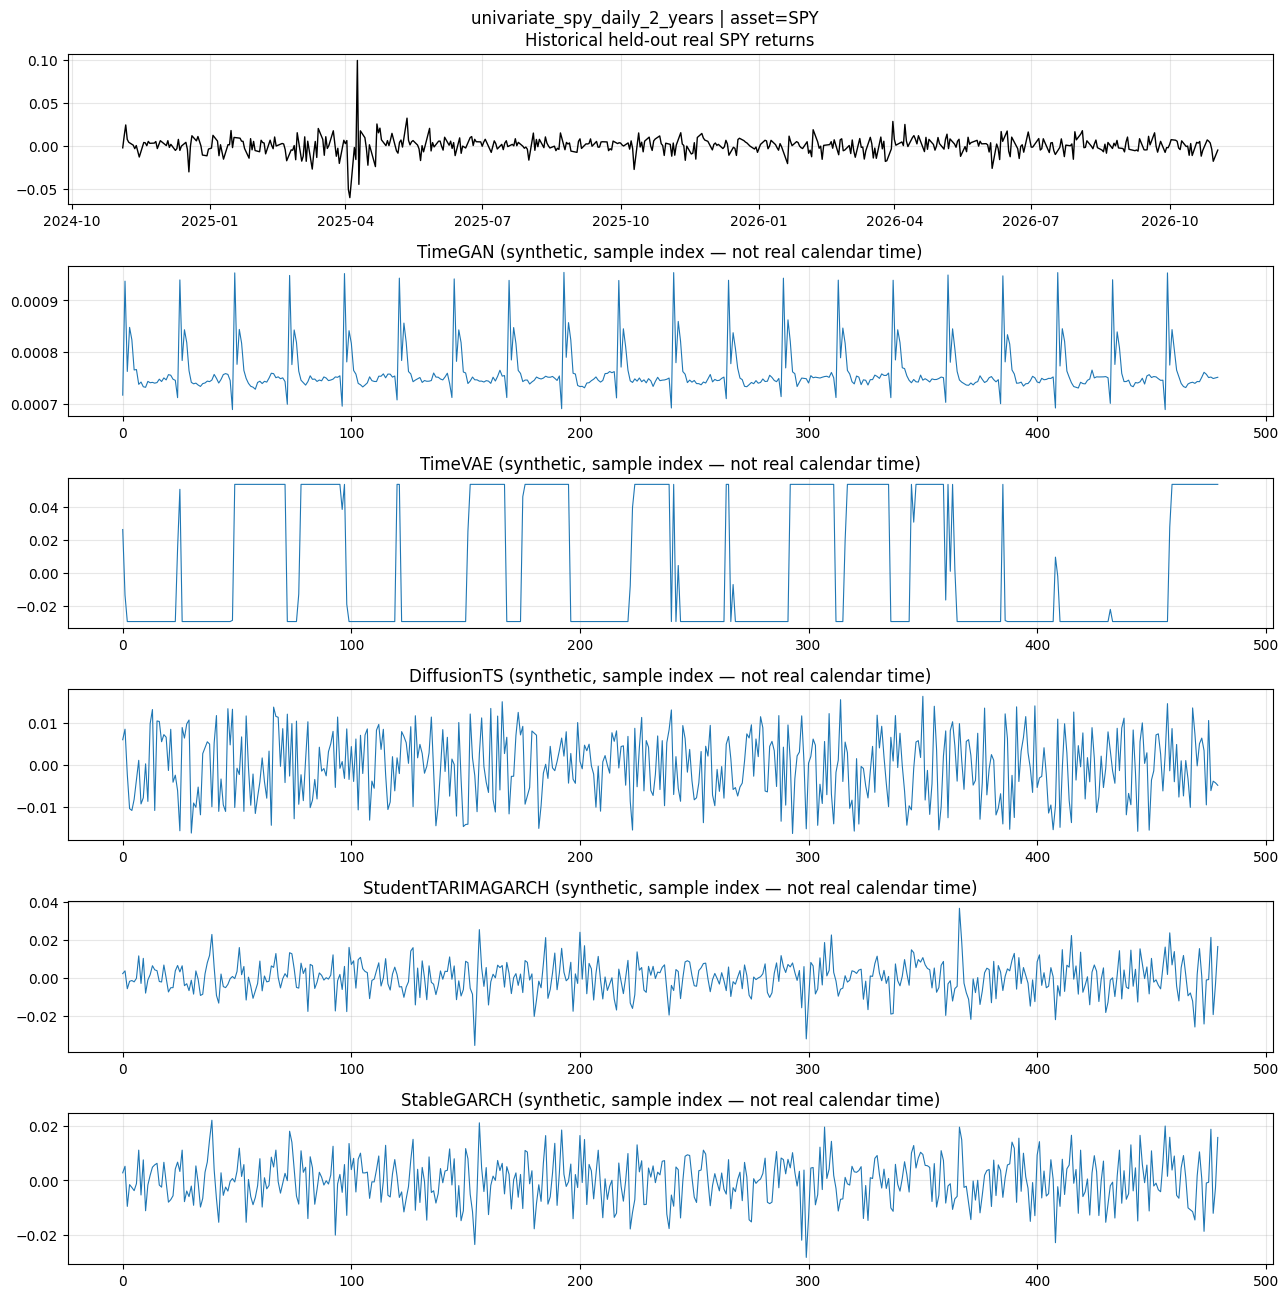

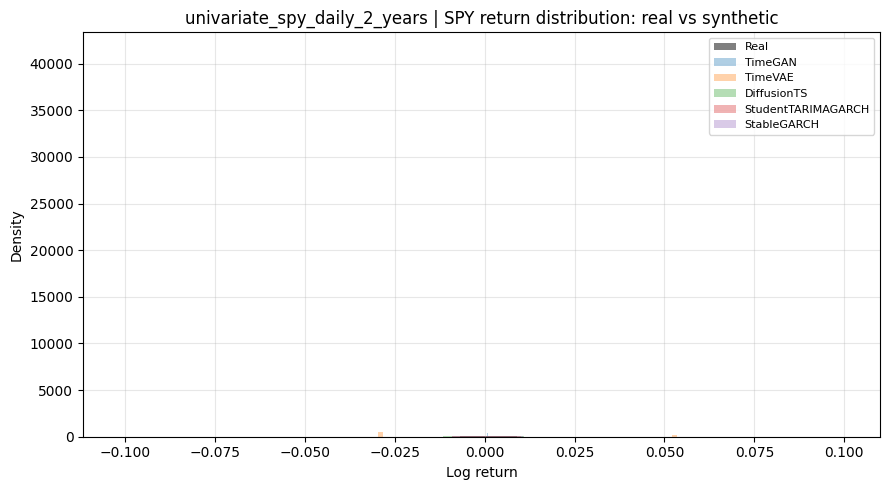

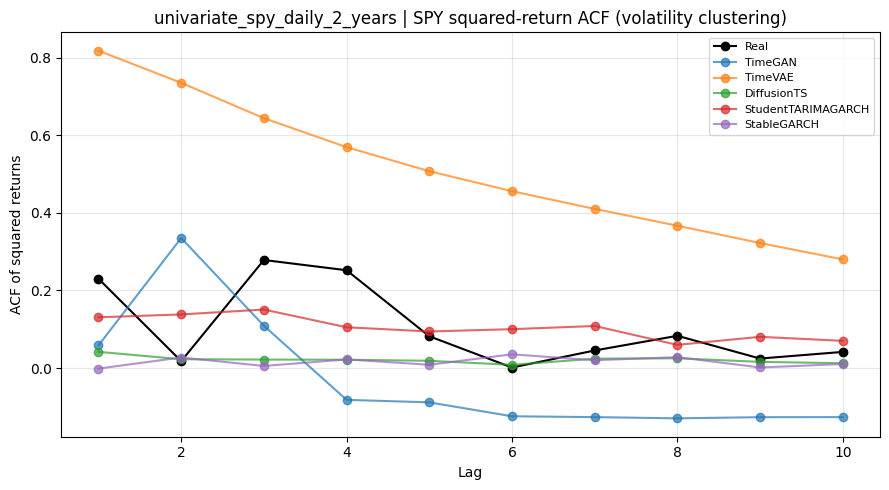

[univariate_spy_daily_5_years] training TimeGAN ...
[univariate_spy_daily_5_years] training TimeVAE ...
[univariate_spy_daily_5_years] training DiffusionTS ...
[univariate_spy_daily_5_years] training StudentTARIMAGARCH ...
[univariate_spy_daily_5_years] training StableGARCH ...

=== univariate_spy_daily_5_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,daily,5_years,108.567224,0.001811,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,1.110223e-16,0.394934,2.157727,0.982055,21.674080,0.004639,0.004639,2.437924,0.530345,jointly trained multivariate generator
1,TimeVAE,univariate_spy,daily,5_years,18.381714,0.002705,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,1.251698e-06,0.430219,85.906214,0.331656,21.991267,0.094433,0.094433,3.103882,0.605764,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,daily,5_years,24.342179,2.174167,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,2.384186e-07,0.304886,1.904880,1.435677,19.764313,0.004395,0.004395,0.609694,0.448076,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,daily,5_years,12.091557,0.002360,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.220446e-16,0.236154,1.766836,0.835532,15.724324,0.000343,0.000343,0.666384,0.395550,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,daily,5_years,1.081015,0.000727,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,1.110223e-16,0.330124,1.493509,0.868964,20.268150,0.004837,0.004837,0.675869,0.440962,univariate per-asset fit: no cross-asset depen...


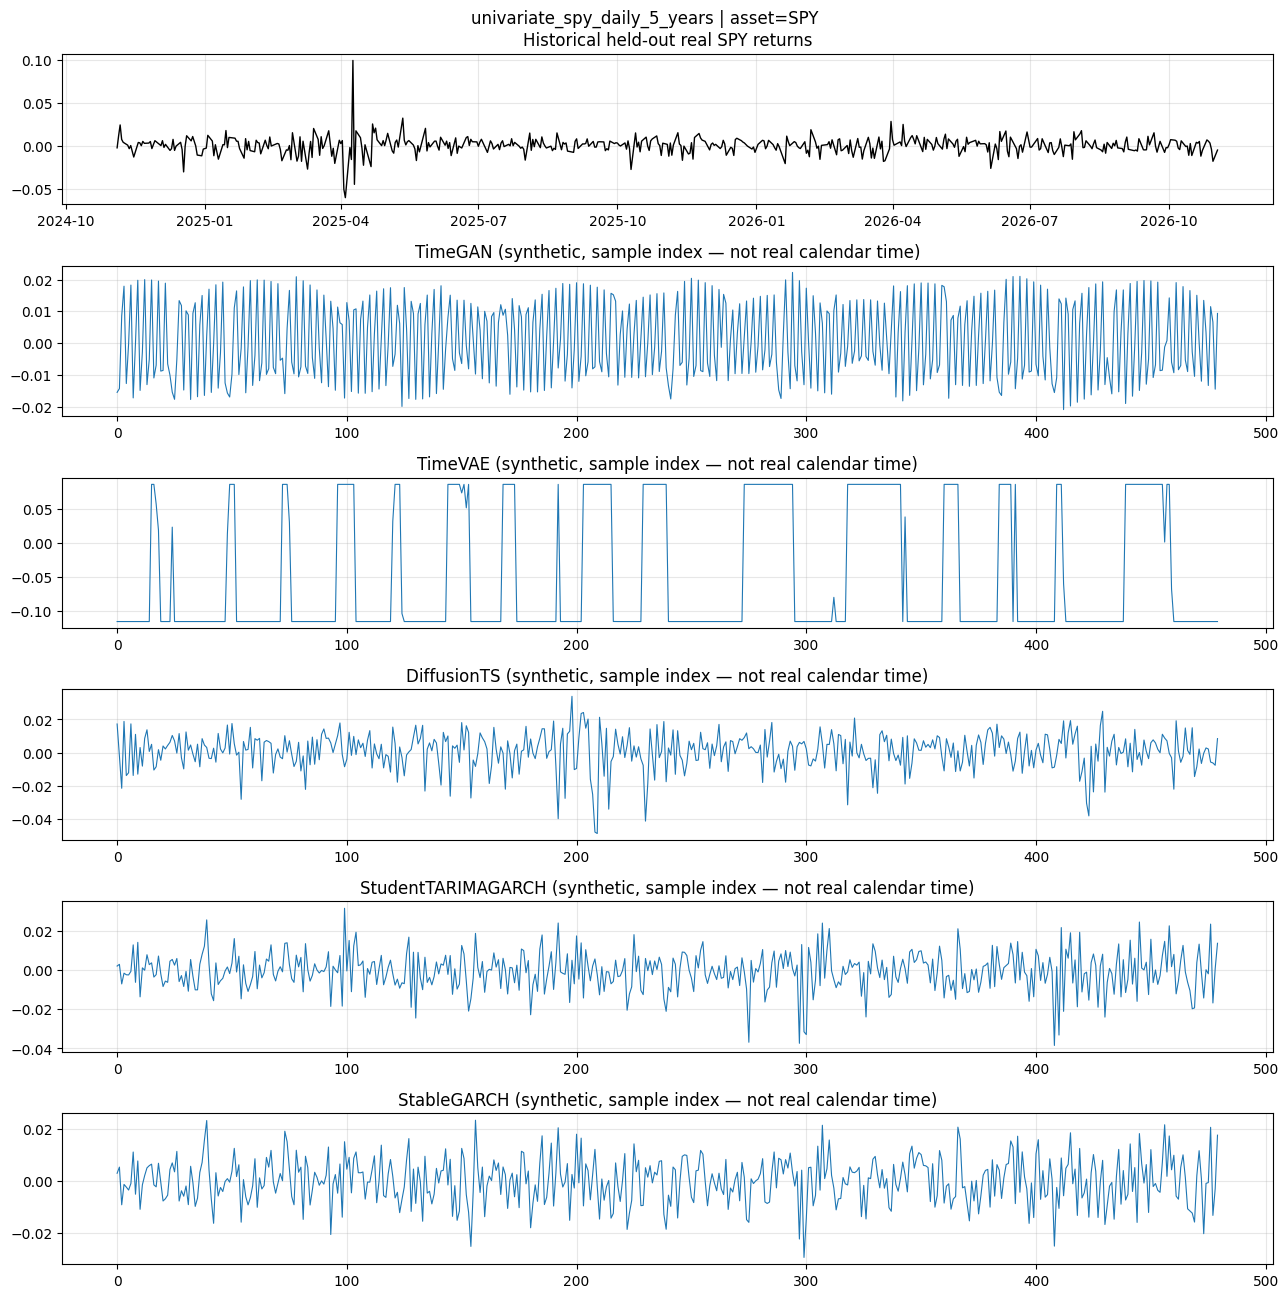

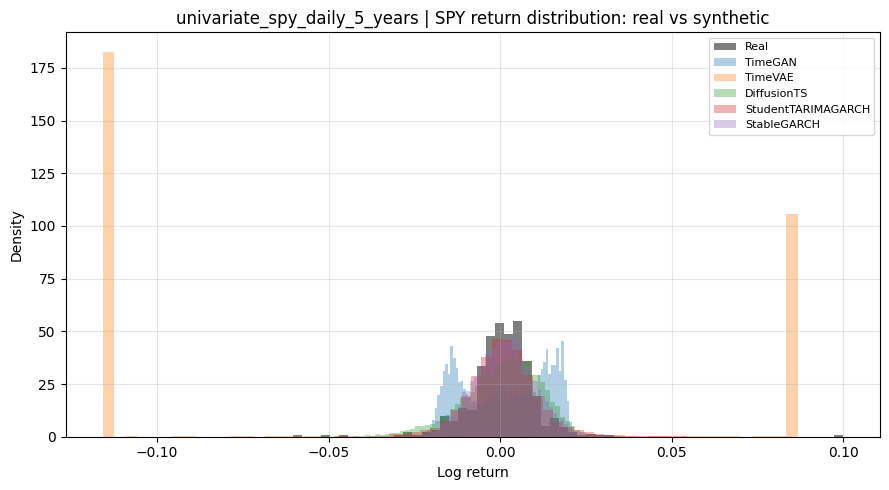

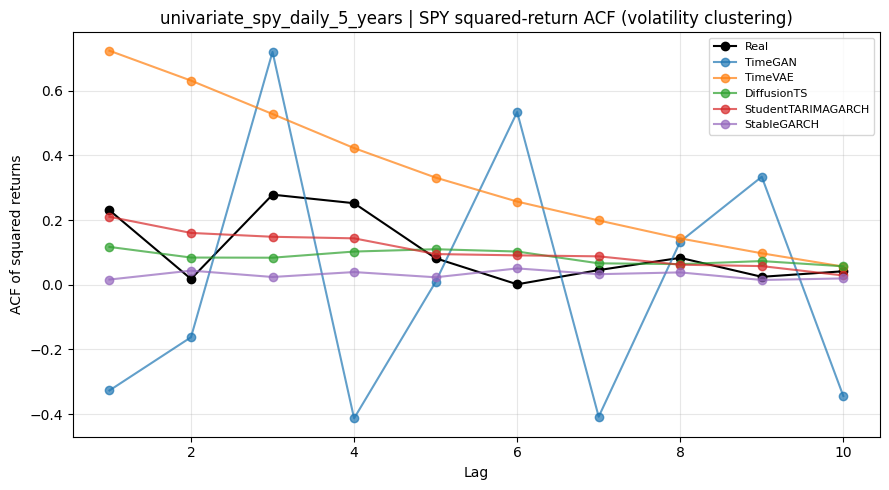

[univariate_spy_daily_8_years] training TimeGAN ...
[univariate_spy_daily_8_years] training TimeVAE ...
[univariate_spy_daily_8_years] training DiffusionTS ...
[univariate_spy_daily_8_years] training StudentTARIMAGARCH ...
[univariate_spy_daily_8_years] training StableGARCH ...

=== univariate_spy_daily_8_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,daily,8_years,193.390646,0.001953,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,1.192093e-07,0.402686,2.049293,0.890711,21.827182,0.005269,0.005269,0.764106,0.496302,jointly trained multivariate generator
1,TimeVAE,univariate_spy,daily,8_years,23.568727,0.001794,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.576279e-06,0.430222,80.618193,0.112136,21.707011,0.094433,0.094433,2.778034,0.588697,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,daily,8_years,39.952865,1.984481,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,0.000000e+00,0.233779,1.111259,1.811079,11.172522,0.012471,0.012471,0.561479,0.459380,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,daily,8_years,9.723924,0.002142,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,0.000000e+00,0.239072,1.438064,0.783400,16.155565,0.004123,0.004123,0.688657,0.417438,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,daily,8_years,2.083125,0.001272,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.220446e-16,0.328448,0.994270,0.867726,20.233287,0.019629,0.019629,0.646565,0.467120,univariate per-asset fit: no cross-asset depen...


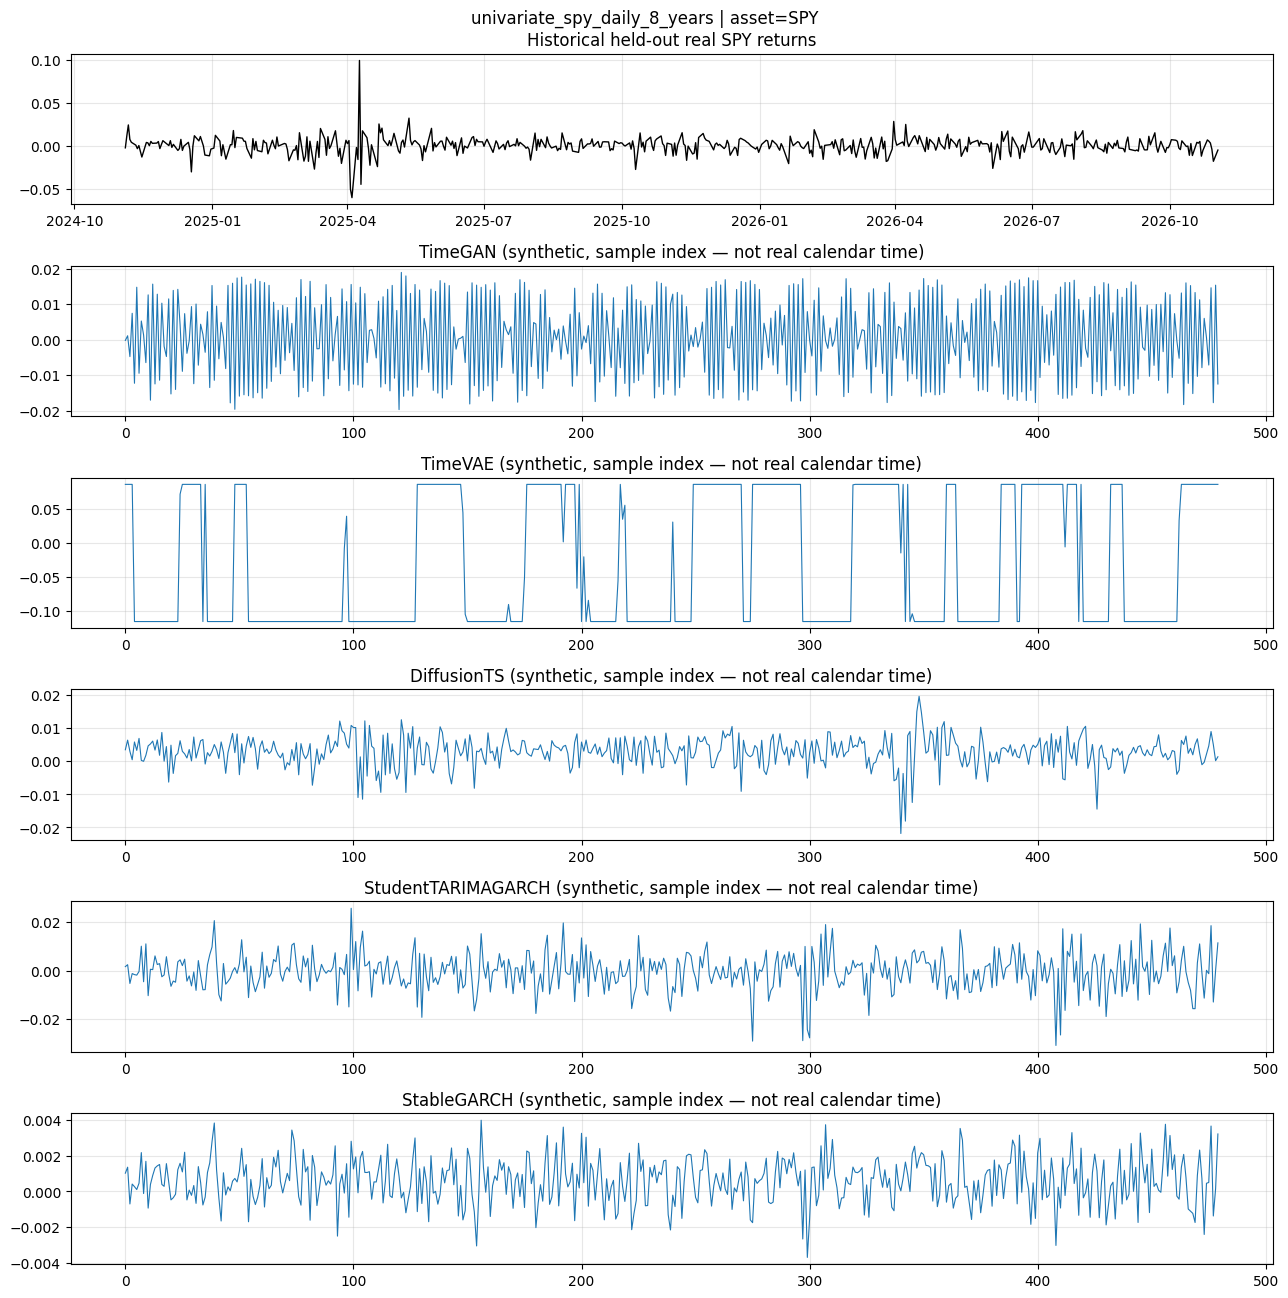

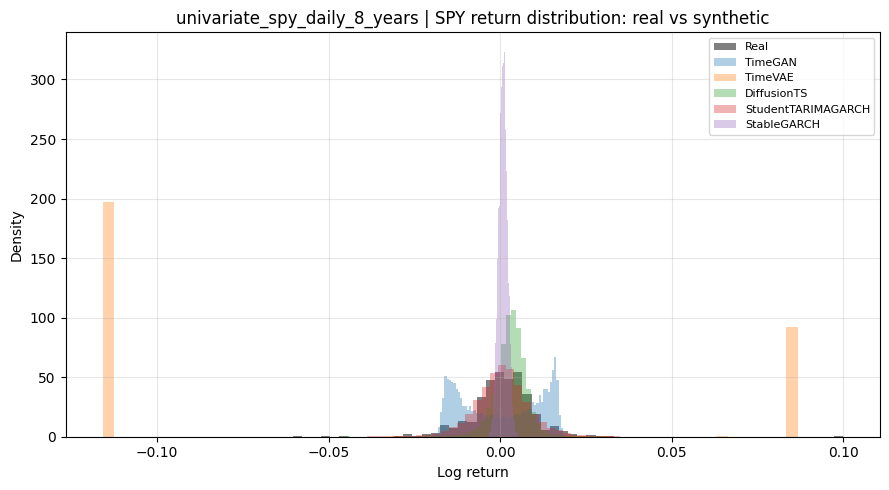

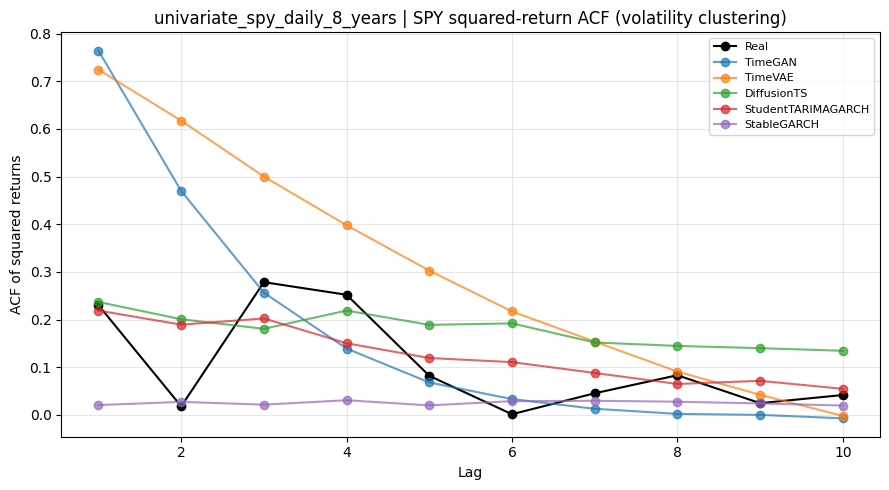

[univariate_spy_hourly_3_months] training TimeGAN ...
[univariate_spy_hourly_3_months] training TimeVAE ...
[univariate_spy_hourly_3_months] training DiffusionTS ...
[univariate_spy_hourly_3_months] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[univariate_spy_hourly_3_months] training StableGARCH ...

=== univariate_spy_hourly_3_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,hourly,3_months,35.583184,0.003747,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,1.192093e-07,0.120496,2.415873,0.613400,5.906548,0.000639,0.000639,1.485385,0.414207,jointly trained multivariate generator
1,TimeVAE,univariate_spy,hourly,3_months,6.838964,0.007216,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,1.609325e-06,0.183501,58.745719,0.862431,6.628869,0.018233,0.018233,2.524773,0.558516,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,hourly,3_months,8.504279,3.567673,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,1.192093e-07,0.119253,1.810081,0.249821,6.010718,0.001741,0.001741,0.385283,0.342577,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,hourly,3_months,2.667493,0.002972,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.220446e-16,0.230961,3.735248,0.107024,141.226751,0.002736,0.002736,0.206122,0.351199,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,hourly,3_months,0.110124,0.006098,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,4.440892e-16,0.273431,2.398372,4.184605,223.232198,0.000298,0.000298,0.212307,0.402441,univariate per-asset fit: no cross-asset depen...


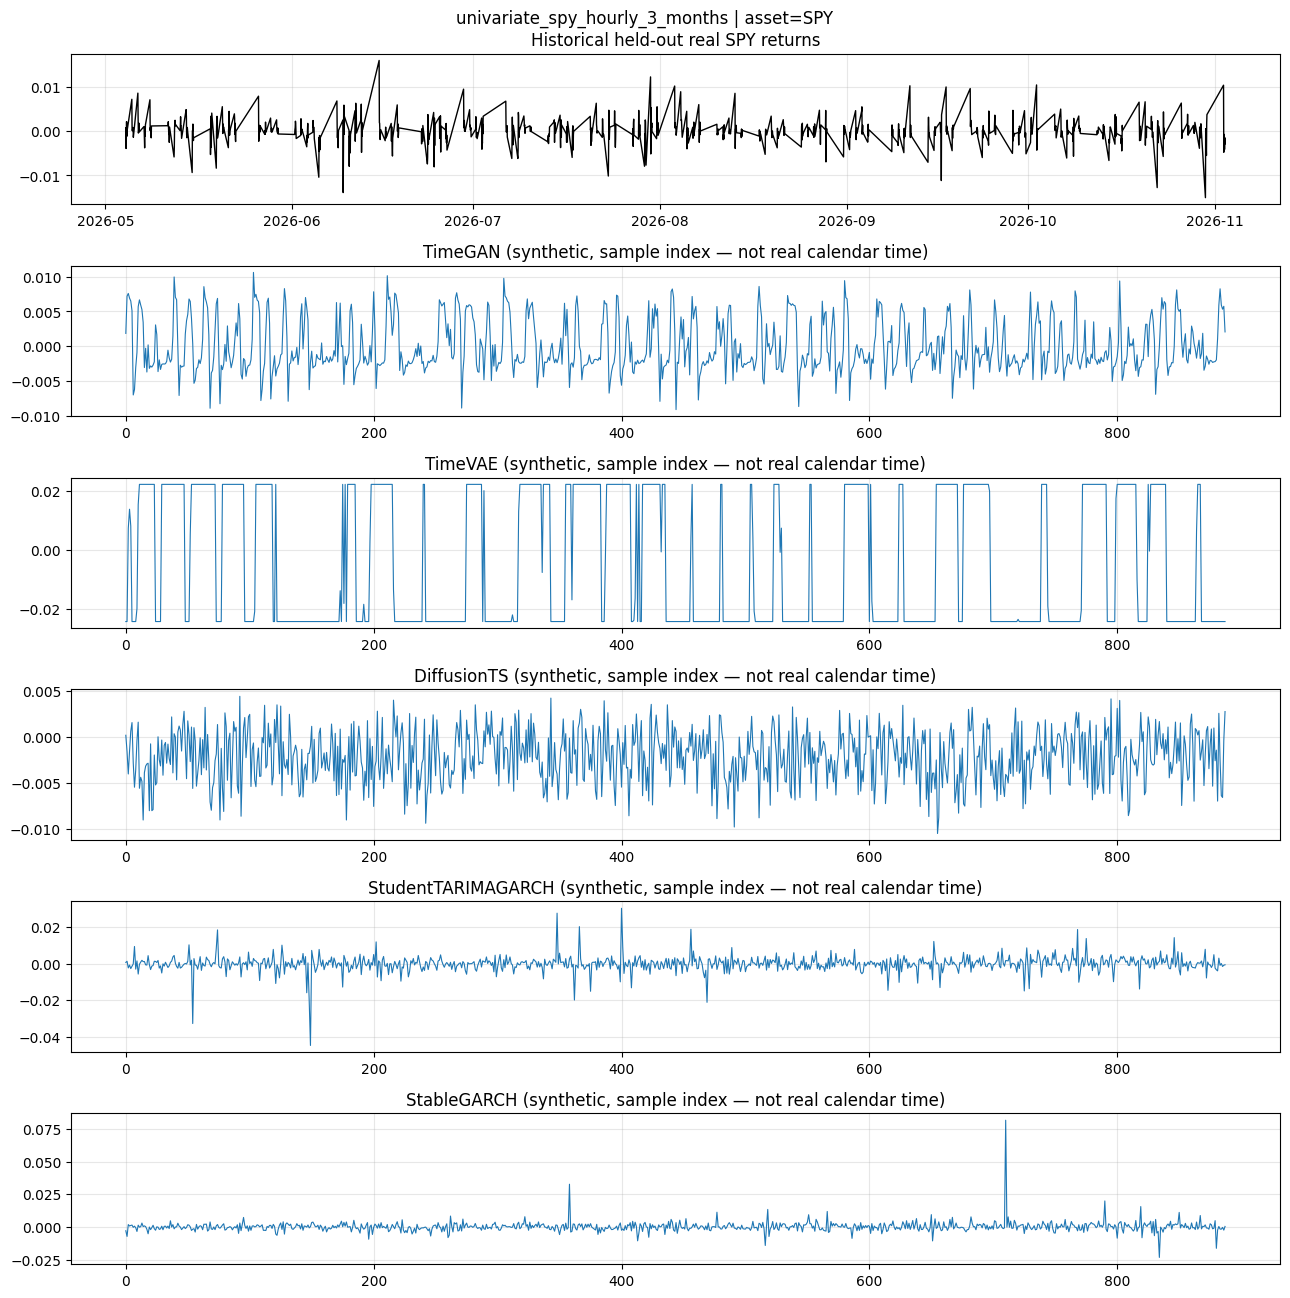

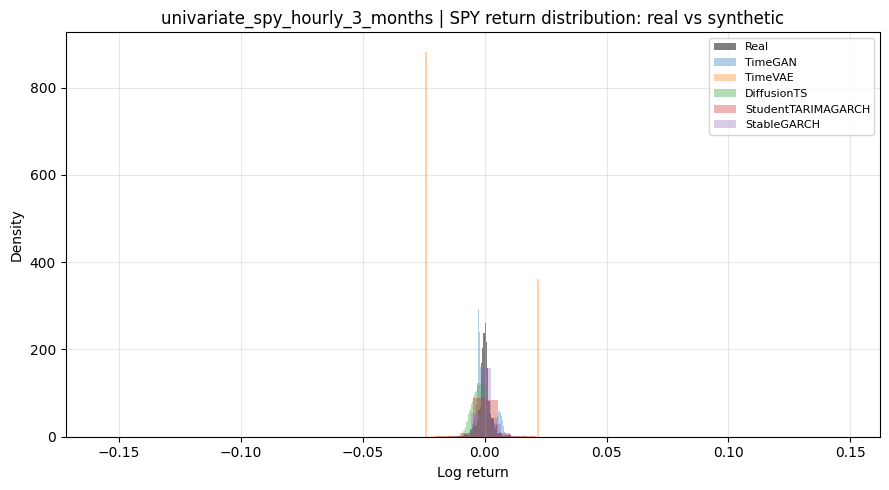

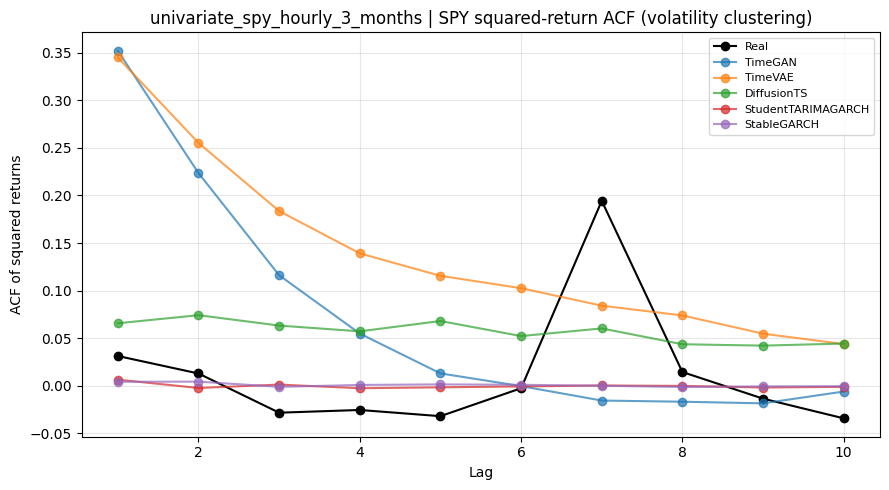

[univariate_spy_hourly_6_months] training TimeGAN ...
[univariate_spy_hourly_6_months] training TimeVAE ...
[univariate_spy_hourly_6_months] training DiffusionTS ...
[univariate_spy_hourly_6_months] training StudentTARIMAGARCH ...
[univariate_spy_hourly_6_months] training StableGARCH ...

=== univariate_spy_hourly_6_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,hourly,6_months,66.350621,0.002962,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,0.000000e+00,0.133765,2.125140,0.316543,6.660816,0.001453,0.001453,0.298054,0.359367,jointly trained multivariate generator
1,TimeVAE,univariate_spy,hourly,6_months,10.348426,0.003160,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,2.086163e-06,0.183501,61.331647,0.752161,6.818881,0.018233,0.018233,2.688000,0.525438,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,hourly,6_months,13.814306,3.451460,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,1.788139e-07,0.115001,3.015361,0.419596,5.738622,0.006698,0.006698,0.363990,0.392392,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,hourly,6_months,4.299677,0.003097,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.220446e-16,0.150087,1.114066,0.305974,3.996746,0.003322,0.003322,0.215986,0.312566,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,hourly,6_months,0.310082,0.004431,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,0.000000e+00,0.205797,1.369531,4.322722,169.972328,0.002457,0.002457,0.216138,0.408789,univariate per-asset fit: no cross-asset depen...


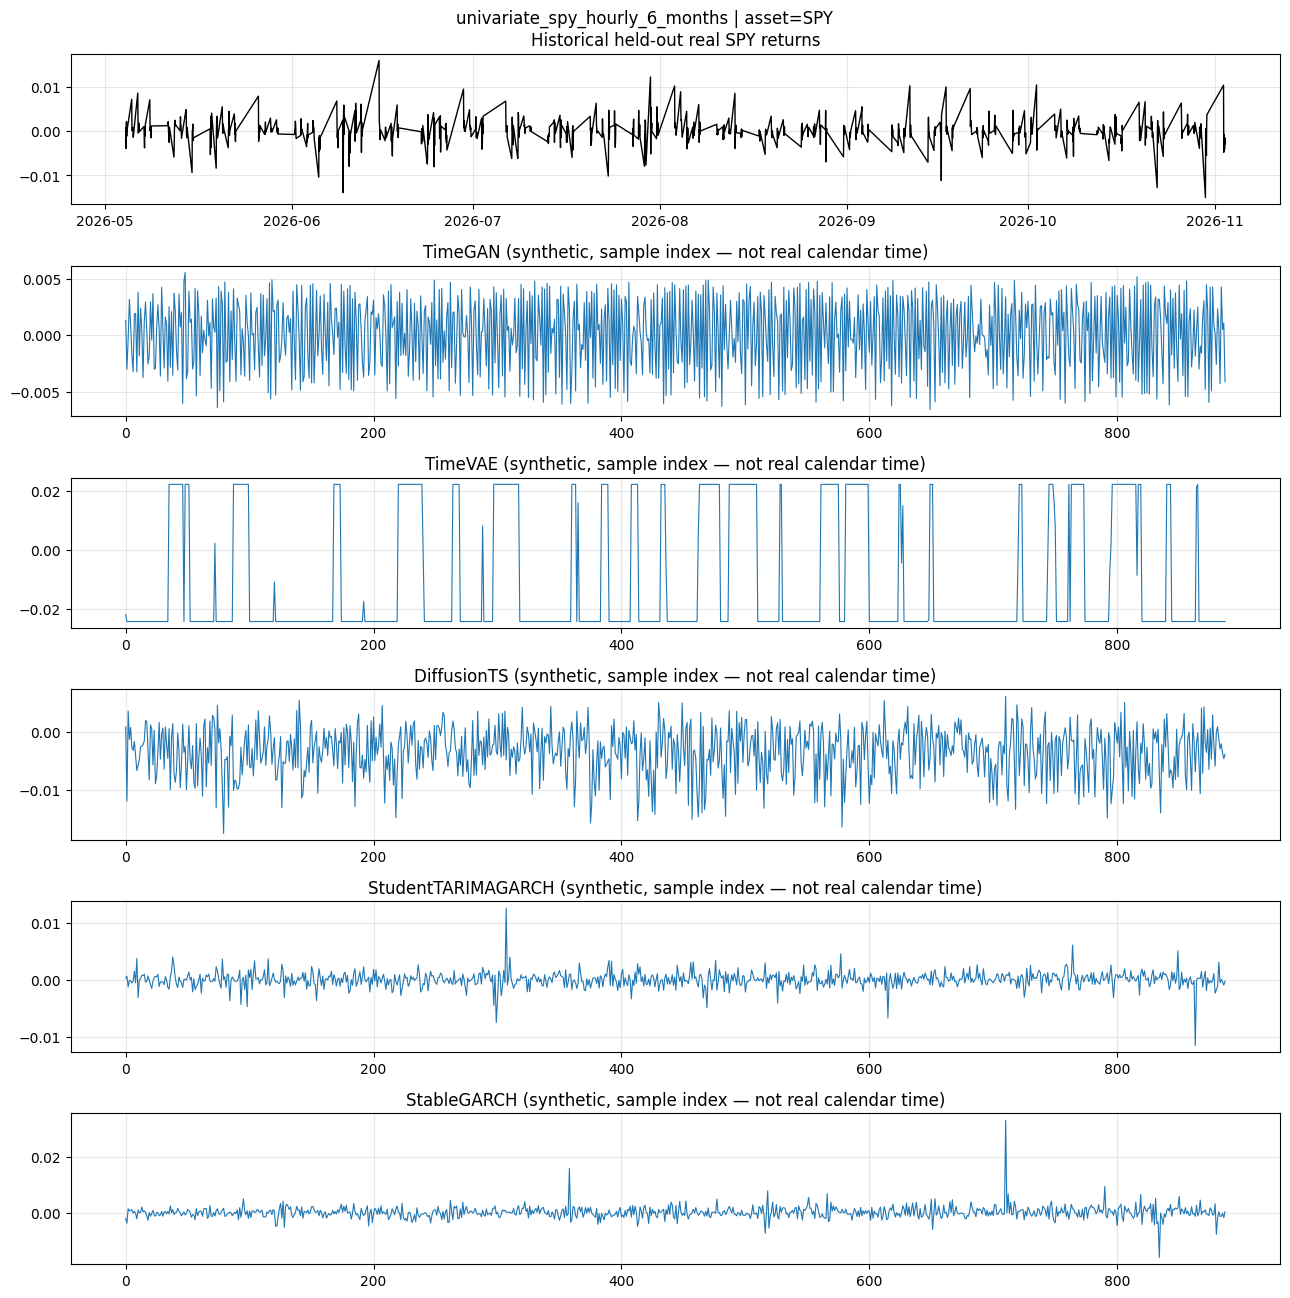

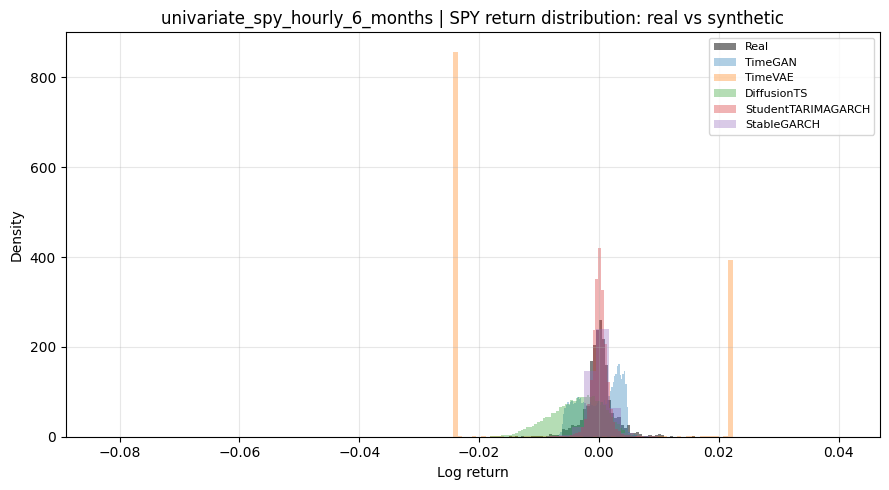

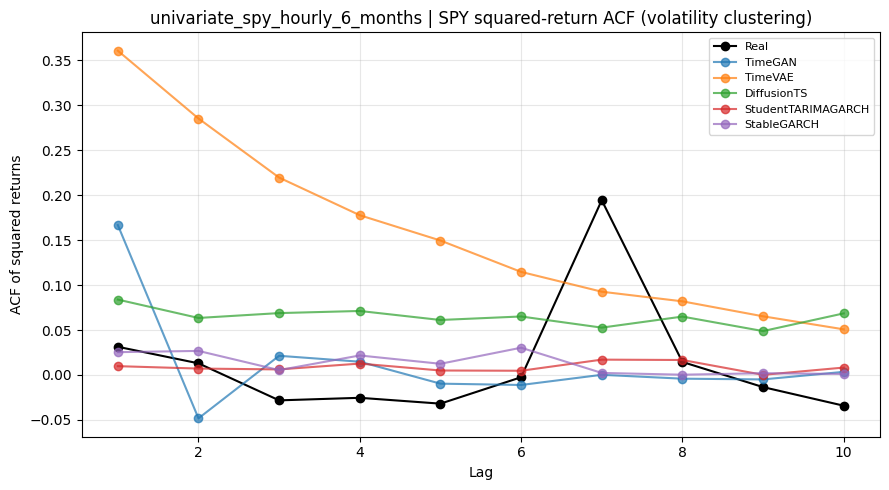

[univariate_spy_hourly_12_months] training TimeGAN ...
[univariate_spy_hourly_12_months] training TimeVAE ...
[univariate_spy_hourly_12_months] training DiffusionTS ...
[univariate_spy_hourly_12_months] training StudentTARIMAGARCH ...
[univariate_spy_hourly_12_months] training StableGARCH ...

=== univariate_spy_hourly_12_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,univariate_spy,hourly,12_months,146.659971,0.003892,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,1.192093e-07,0.125504,2.013207,0.191976,6.621624,0.001470,0.001470,0.276914,0.346126,jointly trained multivariate generator
1,TimeVAE,univariate_spy,hourly,12_months,21.436267,0.003443,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,2.622604e-06,0.183501,73.364554,0.448618,7.202711,0.018233,0.018233,0.236628,0.473111,jointly trained multivariate generator
2,DiffusionTS,univariate_spy,hourly,12_months,35.009271,3.203841,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,1.192093e-07,0.259023,1.125342,4.788316,57.962611,0.004359,0.004359,0.168845,0.419289,jointly trained multivariate generator
3,StudentTARIMAGARCH,univariate_spy,hourly,12_months,8.400150,0.003006,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,0.000000e+00,0.104882,1.723735,0.121113,8.839513,0.000561,0.000561,0.225763,0.297228,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,univariate_spy,hourly,12_months,0.275537,0.003769,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.220446e-16,0.198322,1.216667,3.621379,131.483846,0.003177,0.003177,0.218451,0.408608,univariate per-asset fit: no cross-asset depen...


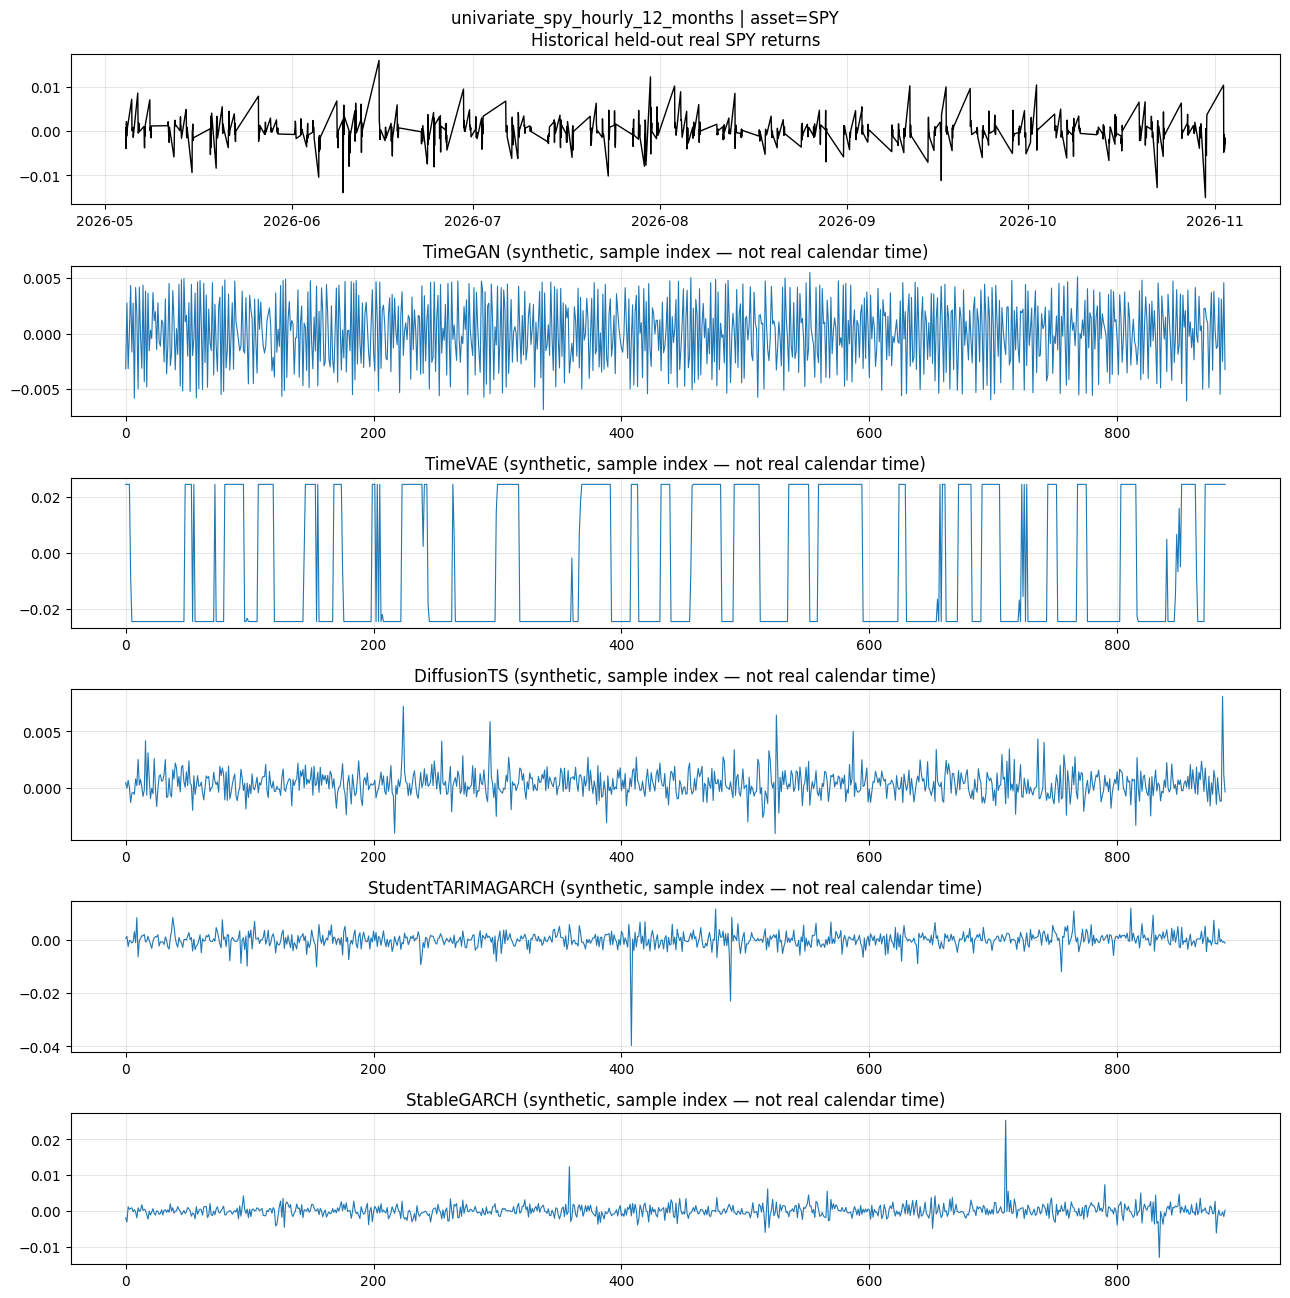

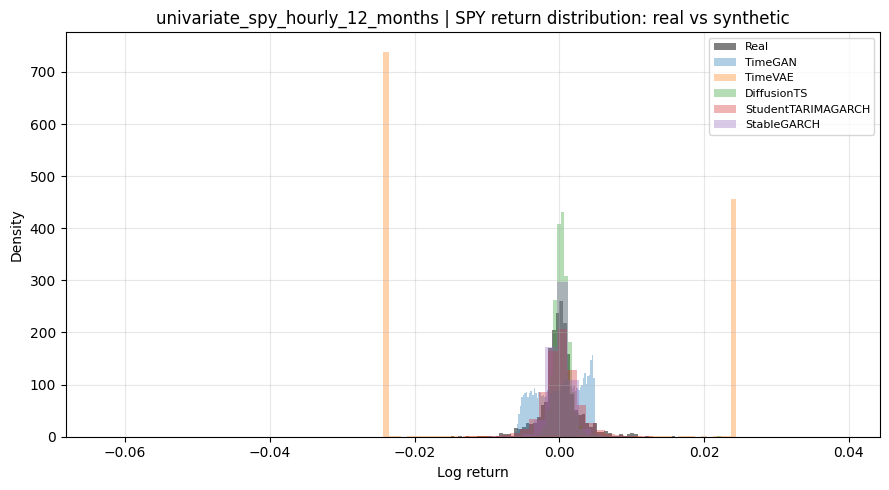

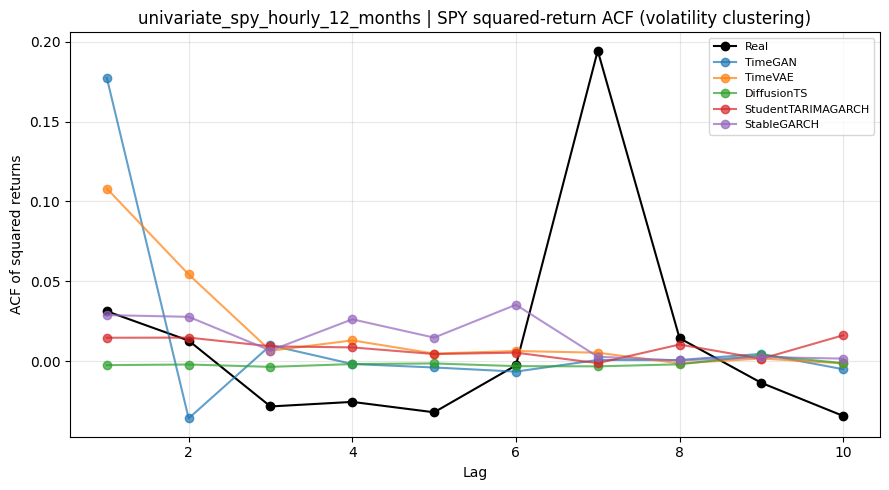

[multivariate_daily_2_years] training TimeGAN ...
[multivariate_daily_2_years] training TimeVAE ...
[multivariate_daily_2_years] training DiffusionTS ...
[multivariate_daily_2_years] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[multivariate_daily_2_years] training StableGARCH ...

=== multivariate_daily_2_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,daily,2_years,38.835500,0.002512,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,2.823733,0.229145,1.558934,0.476871,7.593079,0.011878,0.005613,0.707609,0.591600,jointly trained multivariate generator
1,TimeVAE,multivariate,daily,2_years,5.617105,0.002887,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,2.965698,0.286833,11.165564,0.627892,8.602133,0.012016,0.013700,5.384690,0.715325,jointly trained multivariate generator
2,DiffusionTS,multivariate,daily,2_years,8.365678,1.905722,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,1.964656,0.229847,1.868435,0.586077,7.408791,0.009754,0.004658,0.552580,0.566285,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,daily,2_years,24.401524,0.011618,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.950519,0.169493,1.791231,0.539419,6.246378,0.008317,0.008461,0.517407,0.549766,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,daily,2_years,3.509580,0.005124,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.942350,0.182173,1.921211,0.441830,6.166572,0.009903,0.005294,0.495314,0.550207,univariate per-asset fit: no cross-asset depen...


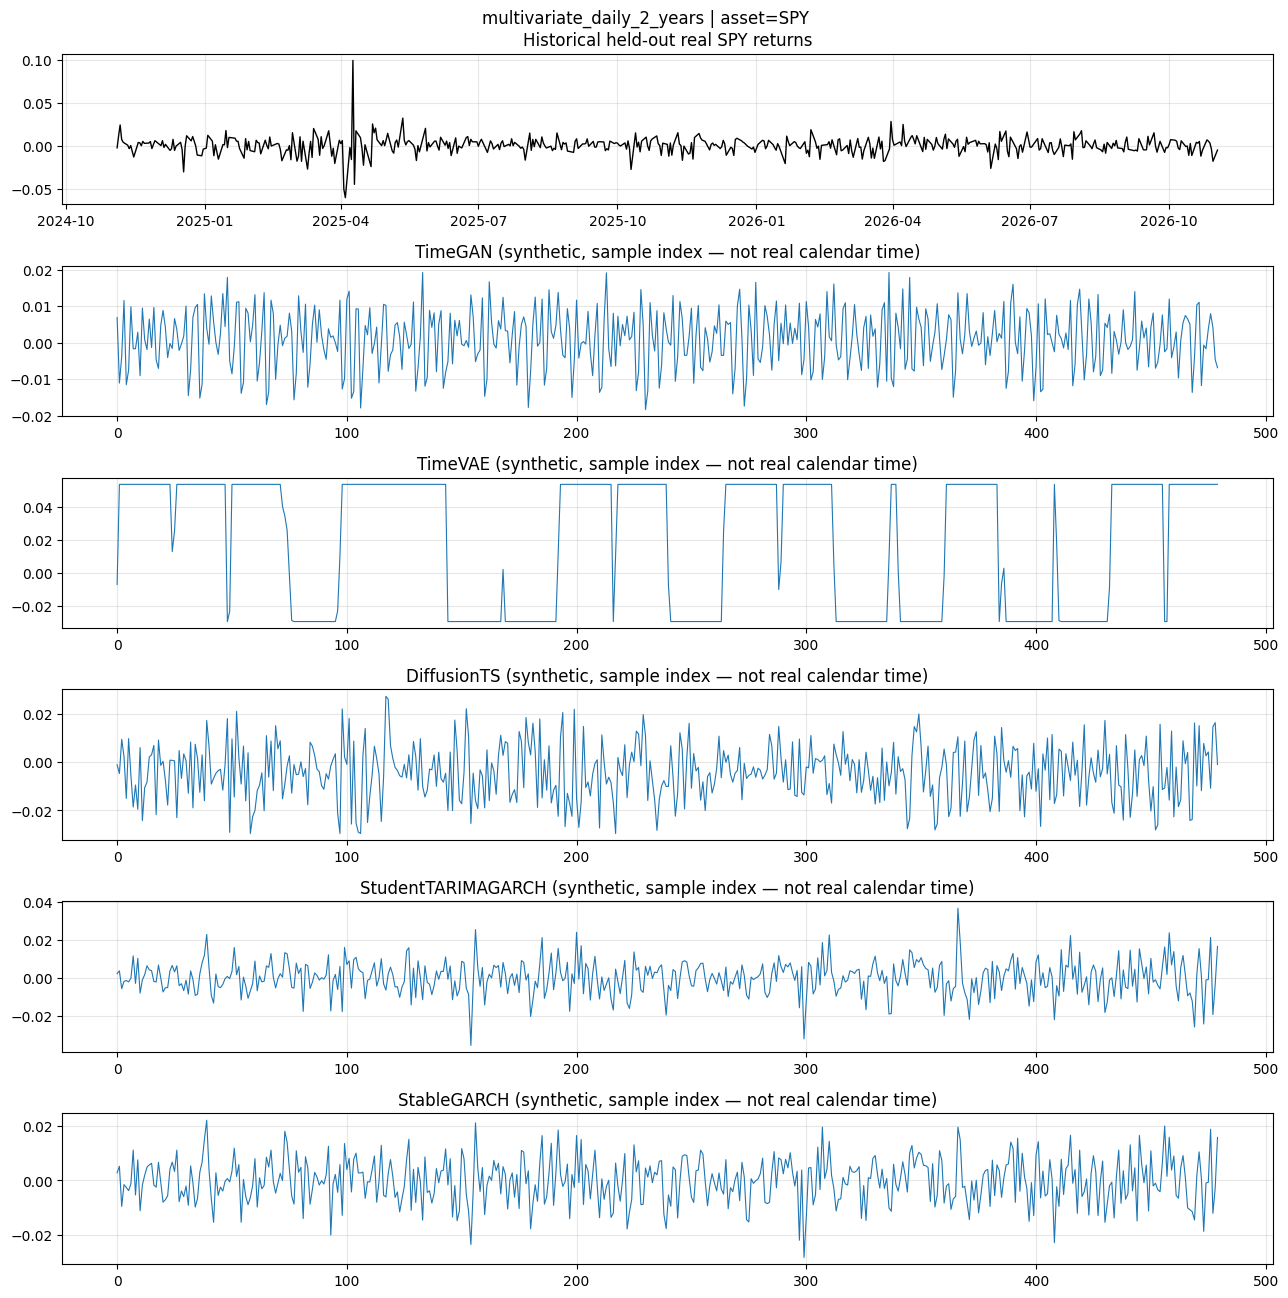

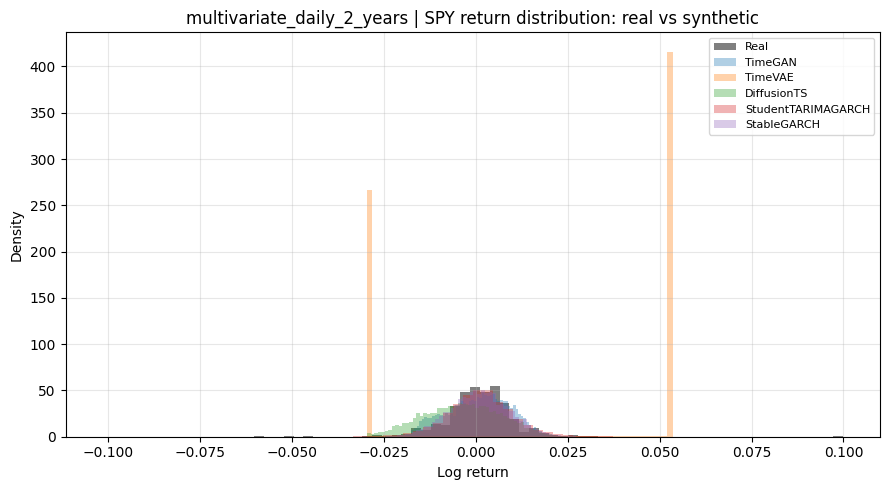

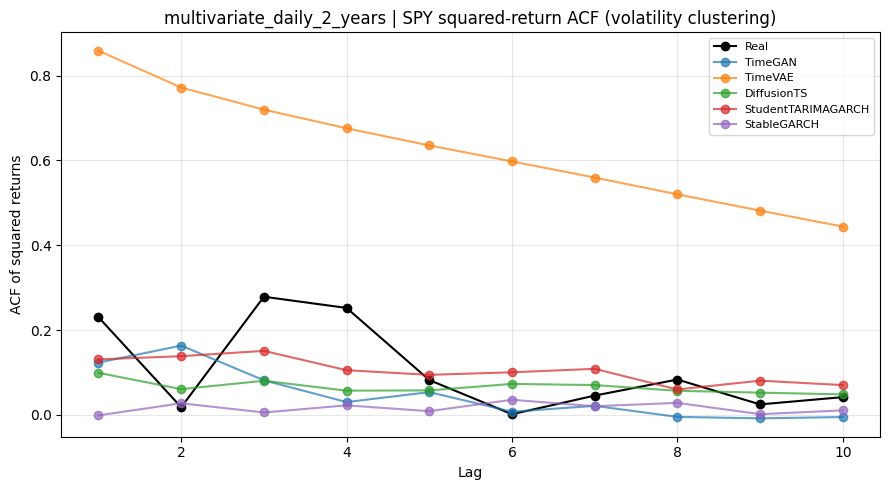

[multivariate_daily_5_years] training TimeGAN ...
[multivariate_daily_5_years] training TimeVAE ...
[multivariate_daily_5_years] training DiffusionTS ...
[multivariate_daily_5_years] training StudentTARIMAGARCH ...
[multivariate_daily_5_years] training StableGARCH ...

=== multivariate_daily_5_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,daily,5_years,104.541604,0.002376,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,3.905953,0.230387,1.934687,0.480128,7.915223,0.008614,0.004318,0.739027,0.608793,jointly trained multivariate generator
1,TimeVAE,multivariate,daily,5_years,15.978929,0.002159,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.082236,0.286831,58.488051,0.576228,8.496727,0.102517,0.107922,4.573704,0.755073,jointly trained multivariate generator
2,DiffusionTS,multivariate,daily,5_years,22.812674,3.041291,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,2.359523,0.340986,1.699614,1.641196,12.027769,0.012953,0.006286,0.504631,0.627425,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,daily,5_years,49.953797,0.011643,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.952932,0.177977,2.090845,0.448920,4.828376,0.006611,0.004292,0.519220,0.533135,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,daily,5_years,8.598902,0.005105,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.940933,0.205161,2.516287,0.456757,5.203424,0.020914,0.004338,0.504942,0.577045,univariate per-asset fit: no cross-asset depen...


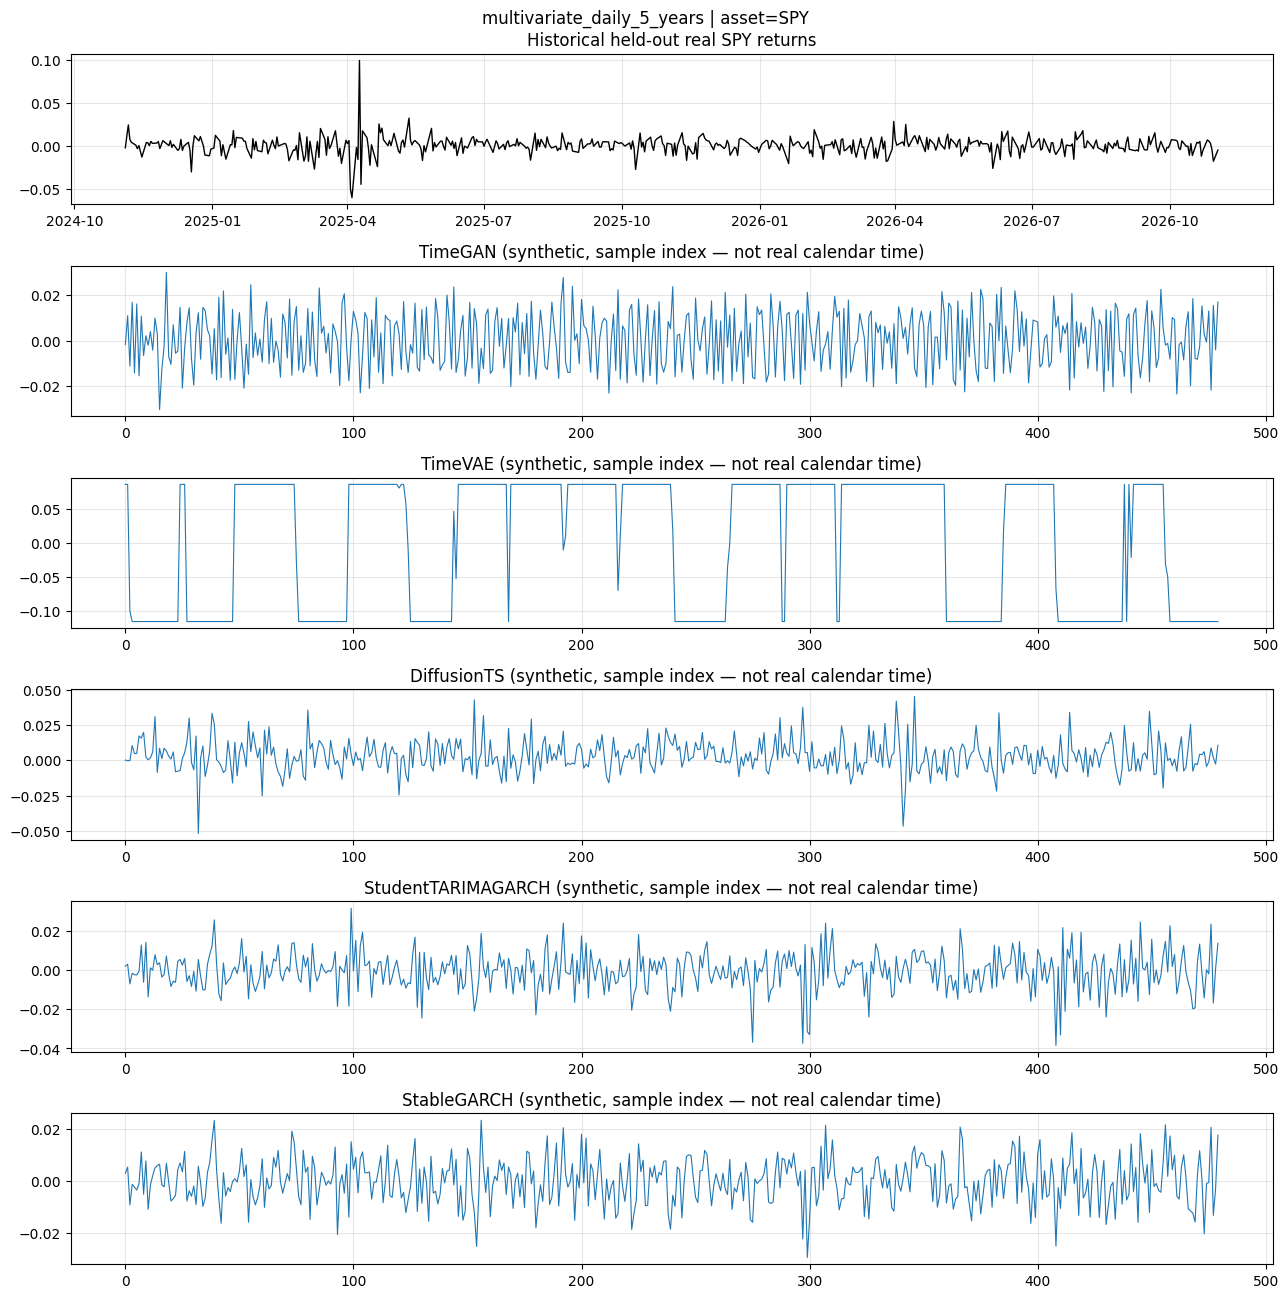

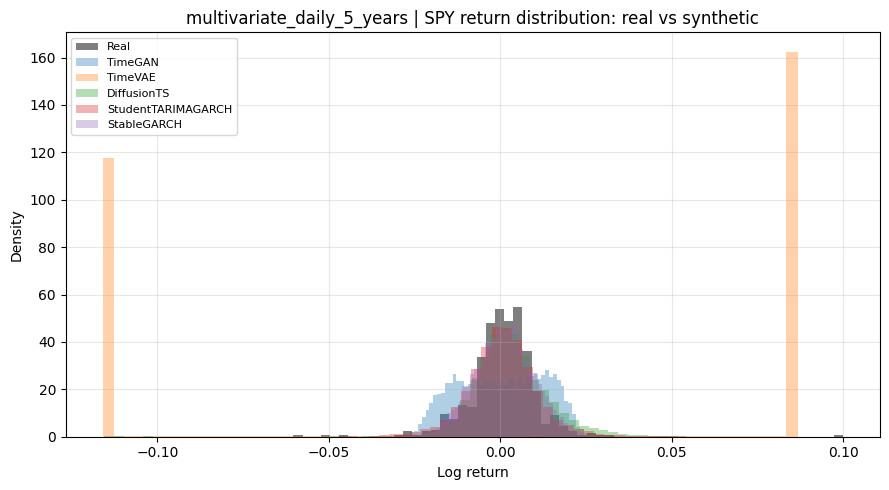

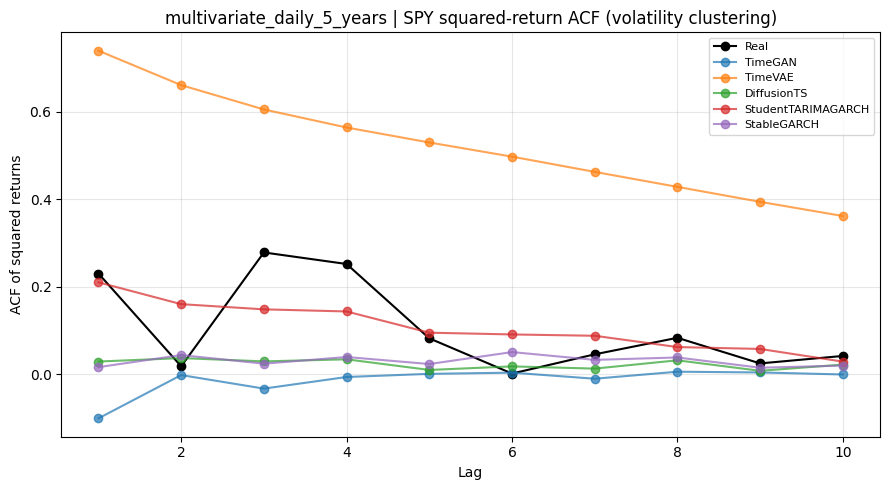

[multivariate_daily_8_years] training TimeGAN ...
[multivariate_daily_8_years] training TimeVAE ...
[multivariate_daily_8_years] training DiffusionTS ...
[multivariate_daily_8_years] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[multivariate_daily_8_years] training StableGARCH ...

=== multivariate_daily_8_years ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,daily,8_years,170.774346,0.003205,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,3.516934,0.250946,1.782494,0.393001,8.498868,0.013309,0.005610,0.781166,0.624594,jointly trained multivariate generator
1,TimeVAE,multivariate,daily,8_years,23.613543,0.002265,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.070975,0.286833,60.069206,0.560993,8.576370,0.102517,0.104131,4.493858,0.752437,jointly trained multivariate generator
2,DiffusionTS,multivariate,daily,8_years,41.965152,1.919652,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,2.273032,0.166491,1.997639,1.784070,8.078216,0.009452,0.010712,0.489937,0.596039,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,daily,8_years,70.850118,0.012428,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,2.946290,0.167115,2.150978,0.458311,3.763834,0.009712,0.005028,0.514743,0.536191,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,daily,8_years,14.758795,0.005204,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,2.947615,0.232332,1.074856,0.429705,6.824937,0.025551,0.015379,0.503585,0.573382,univariate per-asset fit: no cross-asset depen...


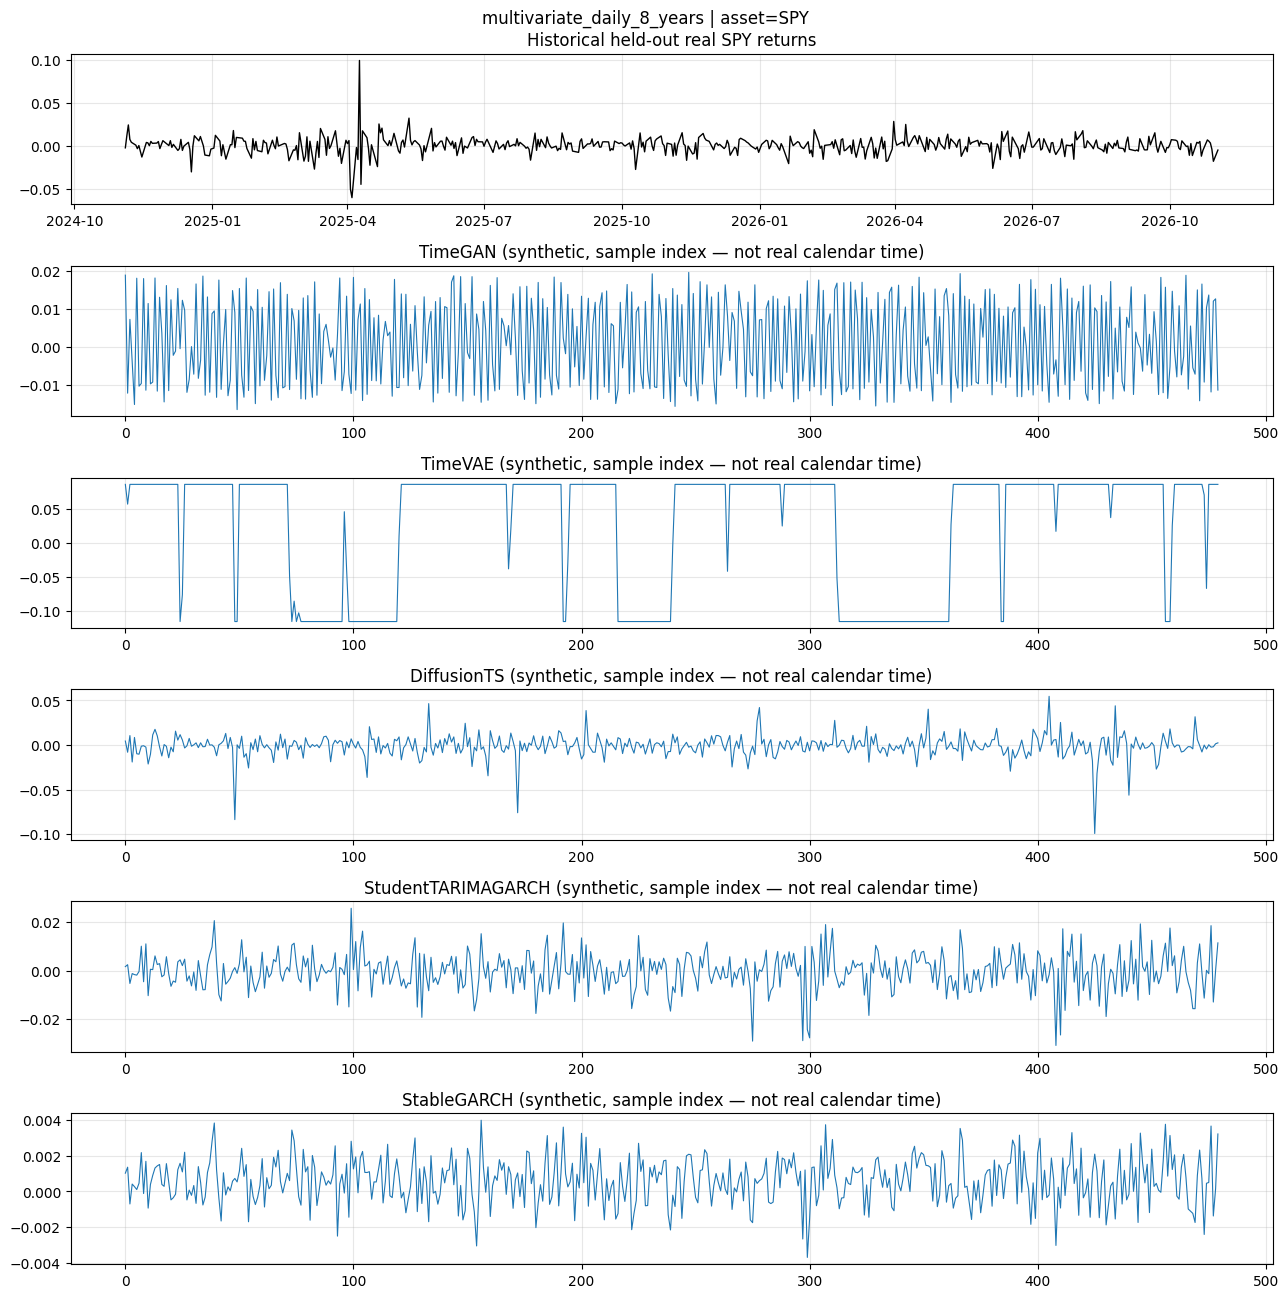

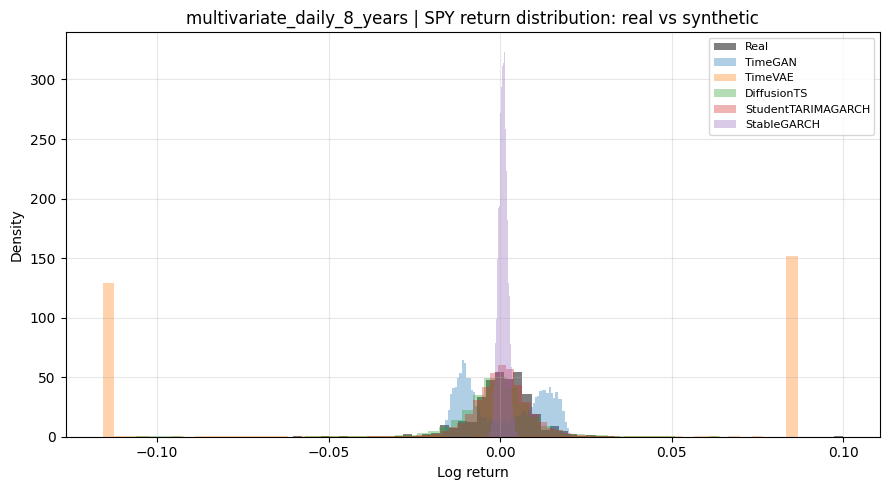

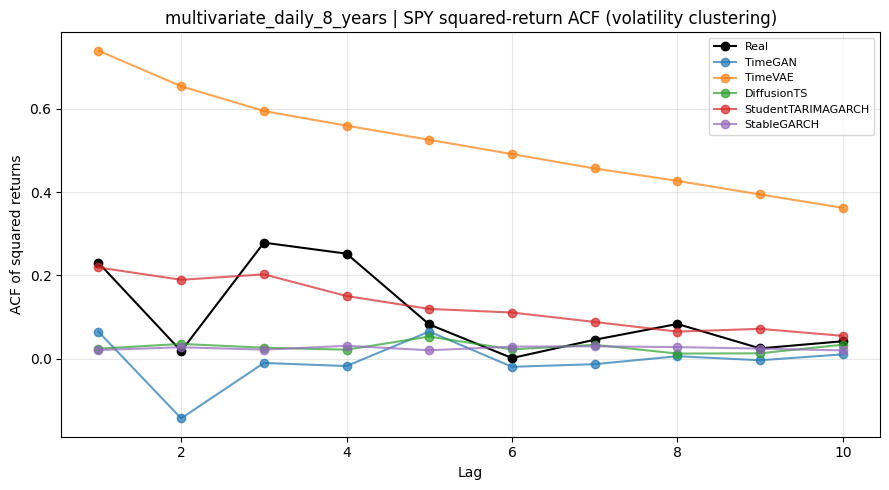

[multivariate_hourly_3_months] training TimeGAN ...
[multivariate_hourly_3_months] training TimeVAE ...
[multivariate_hourly_3_months] training DiffusionTS ...
[multivariate_hourly_3_months] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[multivariate_hourly_3_months] training StableGARCH ...

=== multivariate_hourly_3_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,hourly,3_months,32.960254,0.003625,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,3.326535,0.119170,2.160762,0.352226,9.942529,0.004681,0.002699,0.405255,0.559880,jointly trained multivariate generator
1,TimeVAE,multivariate,hourly,3_months,6.021427,0.005930,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.595021,0.157660,66.295897,0.643939,10.516676,0.039405,0.042989,3.863586,0.738508,jointly trained multivariate generator
2,DiffusionTS,multivariate,hourly,3_months,7.266907,3.342049,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,3.496893,0.131199,1.056832,2.830577,4.503729,0.009651,0.004618,0.380308,0.588389,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,hourly,3_months,13.024755,0.021023,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,3.393264,0.311319,3.166906,6.124768,706.493726,0.001972,0.000293,0.200090,0.585568,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,hourly,3_months,1.869576,0.038282,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,3.389302,0.439127,26.991543,32.416080,3834.292186,0.004230,0.000219,0.192207,0.613887,univariate per-asset fit: no cross-asset depen...


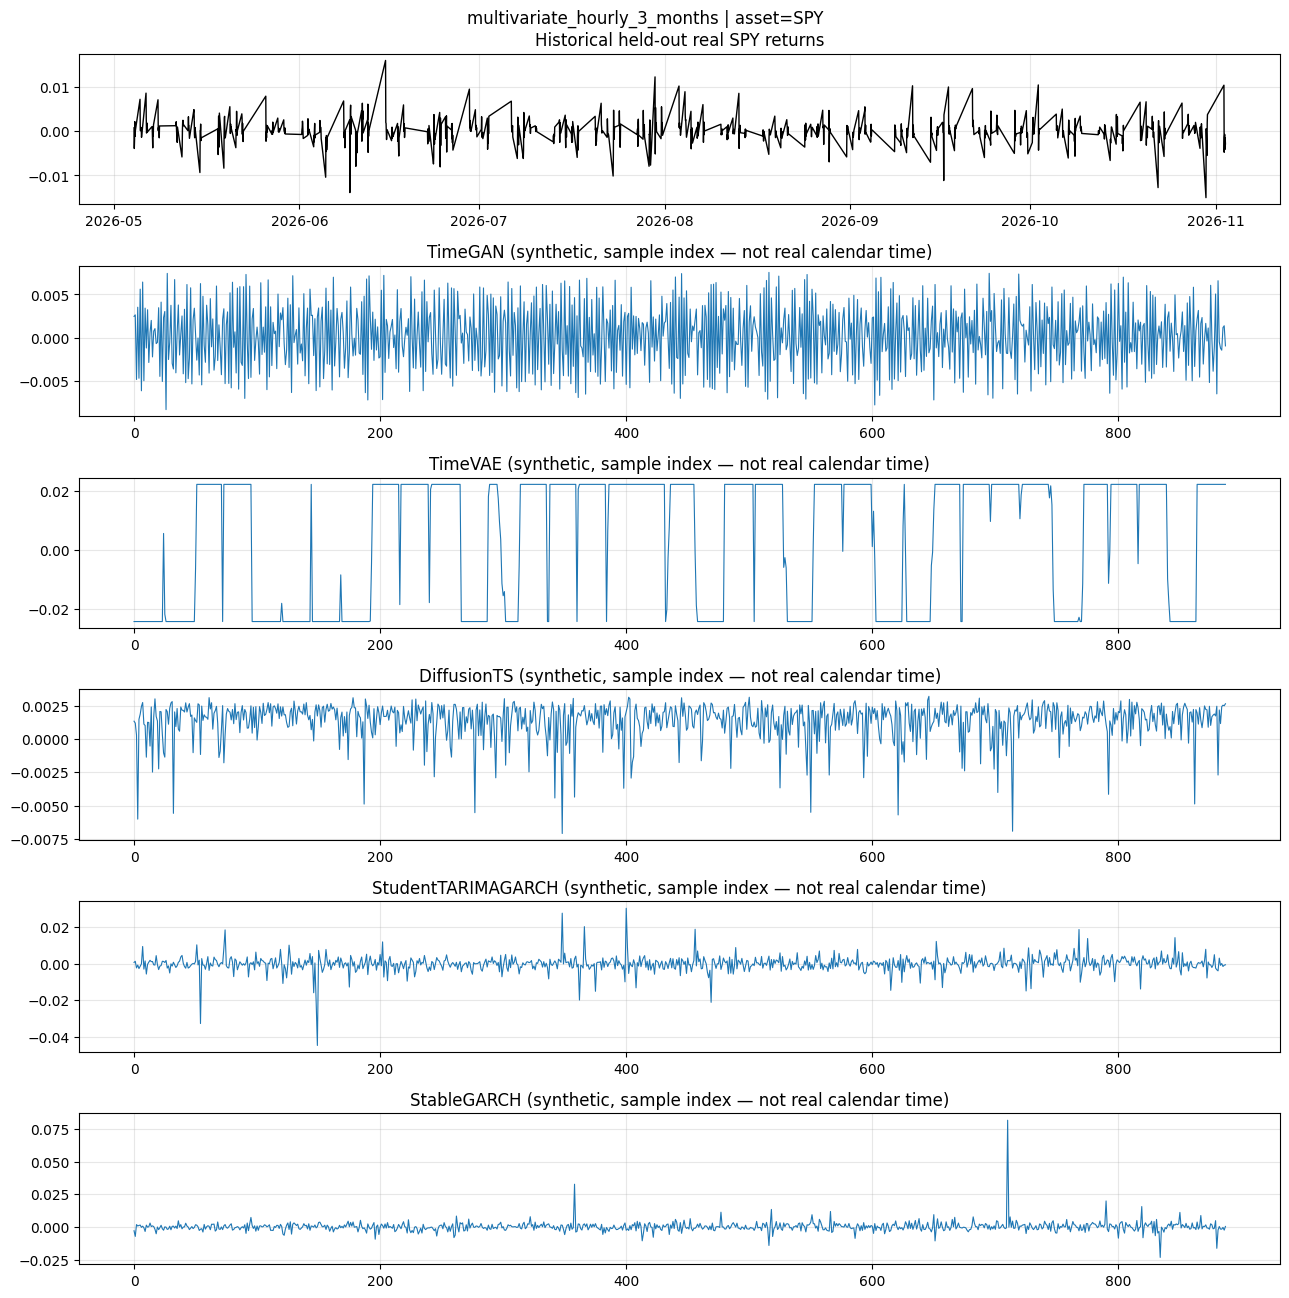

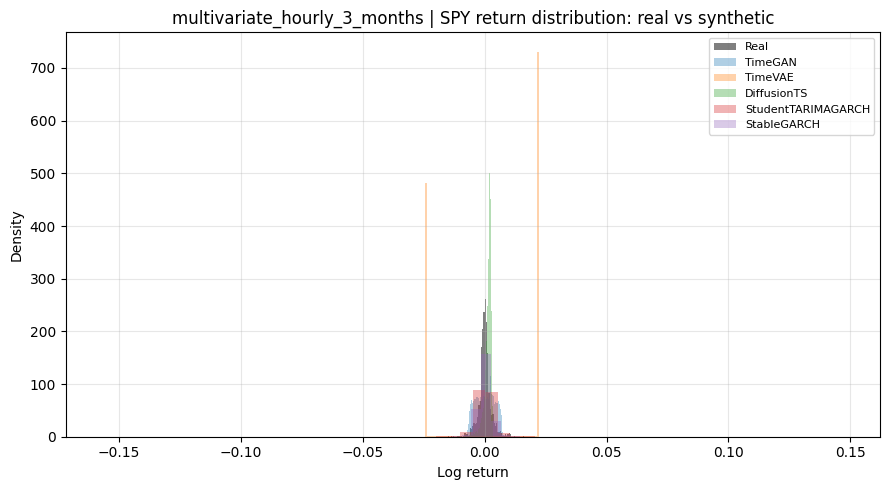

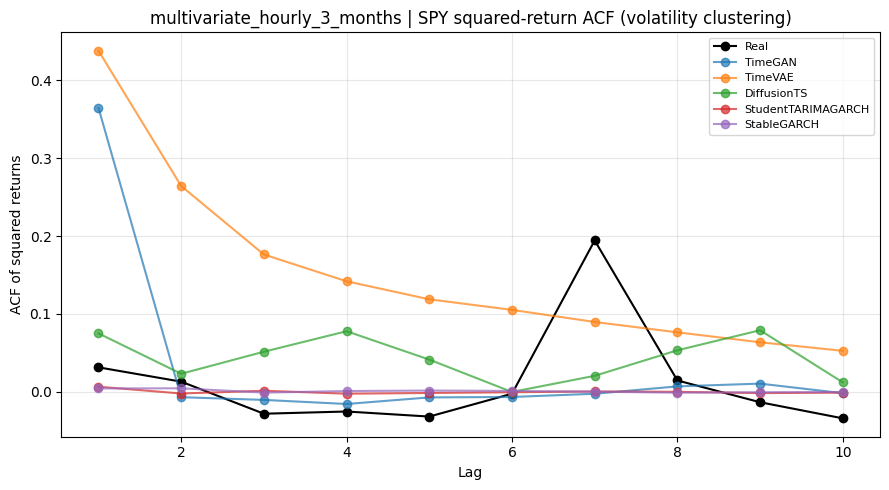

[multivariate_hourly_6_months] training TimeGAN ...
[multivariate_hourly_6_months] training TimeVAE ...
[multivariate_hourly_6_months] training DiffusionTS ...
[multivariate_hourly_6_months] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[multivariate_hourly_6_months] training StableGARCH ...

=== multivariate_hourly_6_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,hourly,6_months,73.432615,0.007989,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,3.395049,0.137286,1.887044,0.363885,10.526010,0.006180,0.003732,0.523615,0.583126,jointly trained multivariate generator
1,TimeVAE,multivariate,hourly,6_months,10.017199,0.004695,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.660061,0.157660,73.517548,0.619314,10.508585,0.043438,0.047023,4.430299,0.741856,jointly trained multivariate generator
2,DiffusionTS,multivariate,hourly,6_months,17.378545,3.307356,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,2.770049,0.130068,1.323582,2.520226,10.580693,0.007637,0.002304,0.564526,0.608317,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,hourly,6_months,47.067136,0.020216,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,3.372247,0.277414,3.979361,6.780025,639.676032,0.006076,0.001991,0.205052,0.613765,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,hourly,6_months,5.875287,0.025455,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,3.391125,0.670177,2.189463,24.765634,2548.878567,0.008528,0.003772,0.214620,0.639382,univariate per-asset fit: no cross-asset depen...


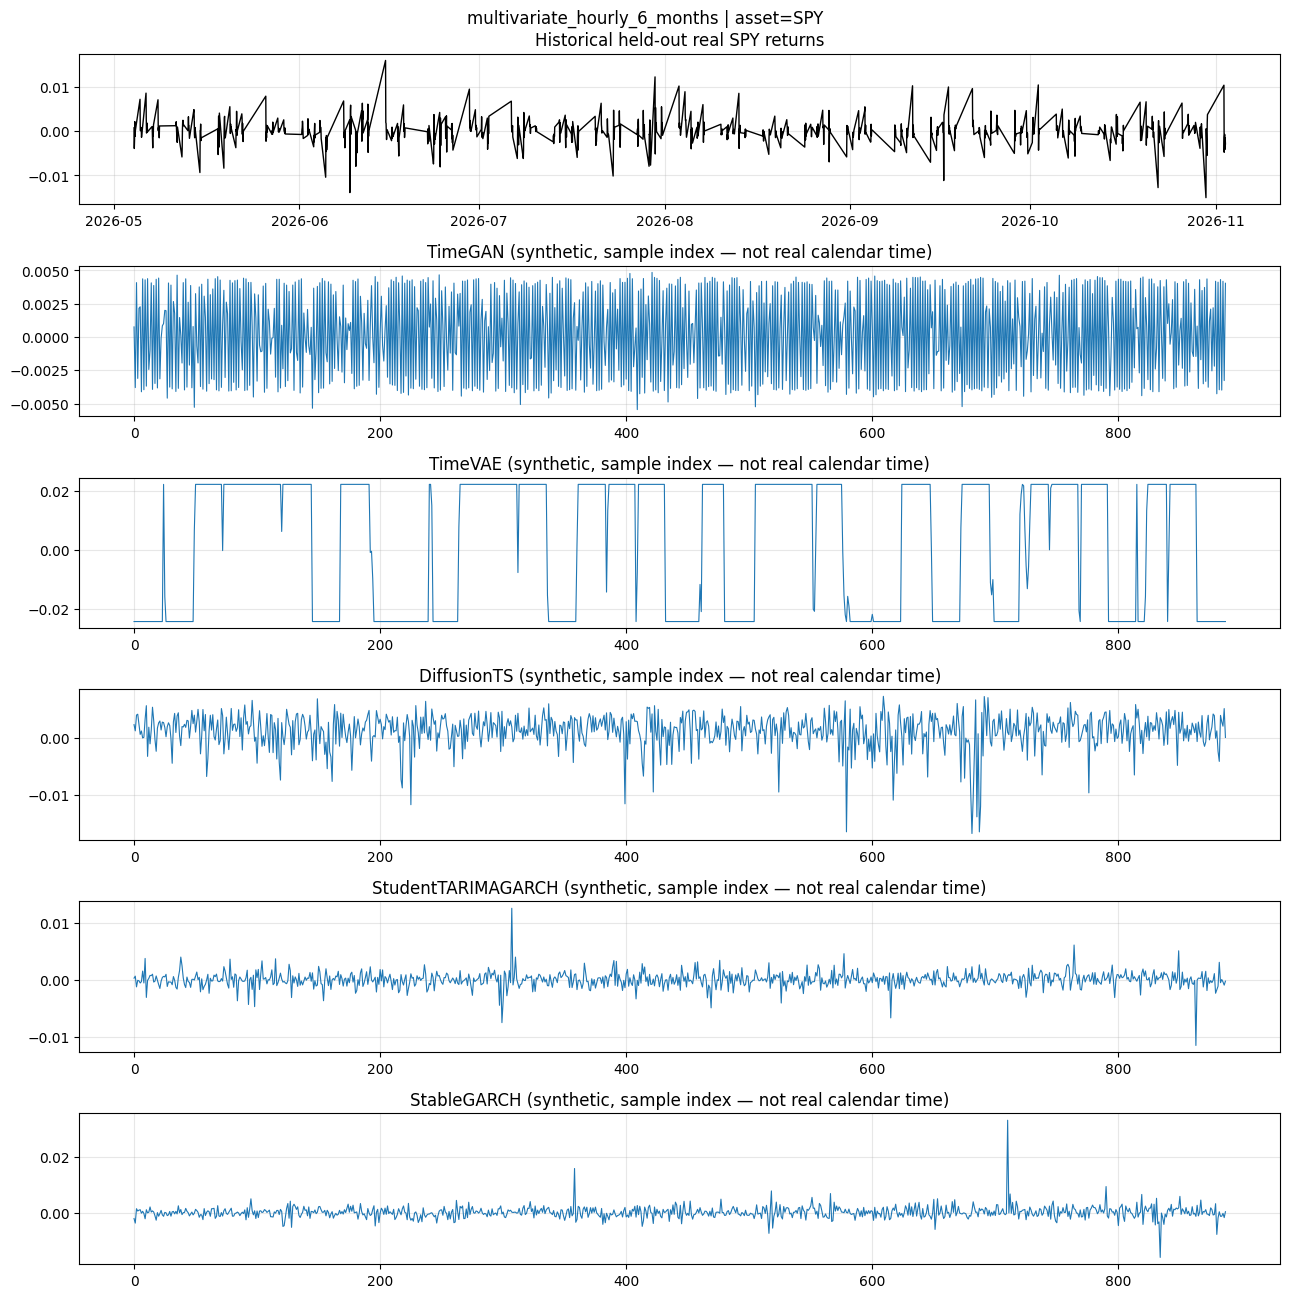

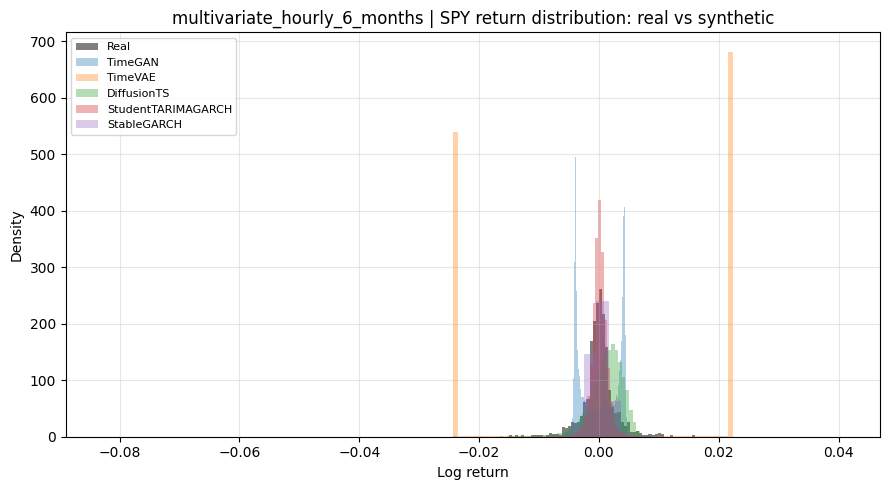

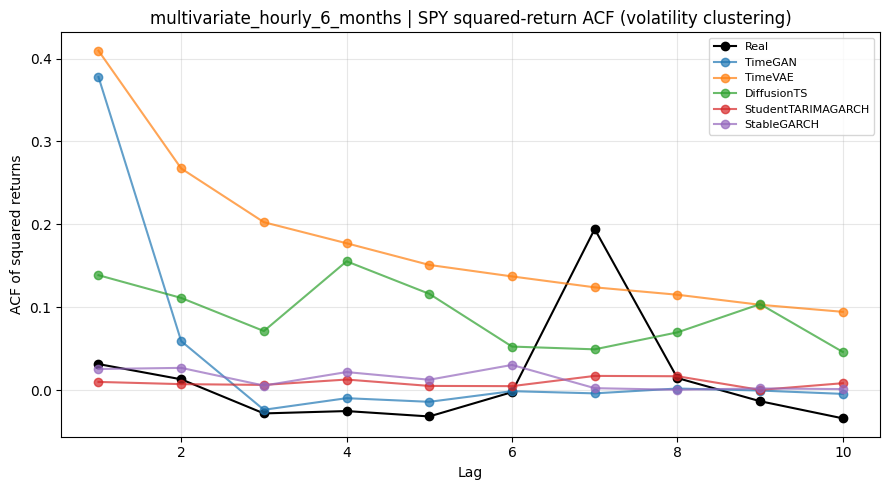

[multivariate_hourly_12_months] training TimeGAN ...
[multivariate_hourly_12_months] training TimeVAE ...
[multivariate_hourly_12_months] training DiffusionTS ...
[multivariate_hourly_12_months] training StudentTARIMAGARCH ...


/home/lonewolf/home/envs/financial-rag/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


[multivariate_hourly_12_months] training StableGARCH ...

=== multivariate_hourly_12_months ===


,Model,Data Configuration,Frequency,Training Duration,Training Time,Sampling Time,Model Status,Error Message,Preprocessing,Training Budget Note,...,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,var_error_portfolio,leverage_effect_error,Composite Error Score,Note
0,TimeGAN,multivariate,hourly,12_months,145.091114,0.004956,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...","Paper's Stocks experiment uses ~10,000-50,000 ...",...,2.000086,0.124942,1.622849,0.424809,10.354651,0.006201,0.002628,0.508484,0.539915,jointly trained multivariate generator
1,TimeVAE,multivariate,hourly,12_months,23.540469,0.005981,ok,,"Internal per-feature MinMaxScaler to [0,1], fi...",Official repo typically trains a few hundred e...,...,3.702216,0.157660,75.996099,0.519995,10.501305,0.043438,0.046337,3.701744,0.735110,jointly trained multivariate generator
2,DiffusionTS,multivariate,hourly,12_months,35.968217,3.306752,ok,,"Internal per-feature MinMaxScaler to [0,1] the...",Official repo commonly trains thousands of ite...,...,1.834954,0.129563,1.668456,3.327054,46.106858,0.007022,0.002295,0.240317,0.554434,jointly trained multivariate generator
3,StudentTARIMAGARCH,multivariate,hourly,12_months,74.529865,0.020808,ok,,No rescaling: operates directly on raw log ret...,"Fit by direct numerical MLE (scipy L-BFGS-B), ...",...,3.392379,0.275534,1.902268,4.433428,520.533305,0.004632,0.002568,0.208683,0.589578,univariate per-asset fit: no cross-asset depen...
4,StableGARCH,multivariate,hourly,12_months,10.306824,0.034752,ok,,No rescaling: operates directly on raw log ret...,Fit by least-squares (AVGARCH) plus a quantile...,...,3.390483,0.543598,1.501458,27.618937,3097.876656,0.009799,0.004687,0.188766,0.626175,univariate per-asset fit: no cross-asset depen...


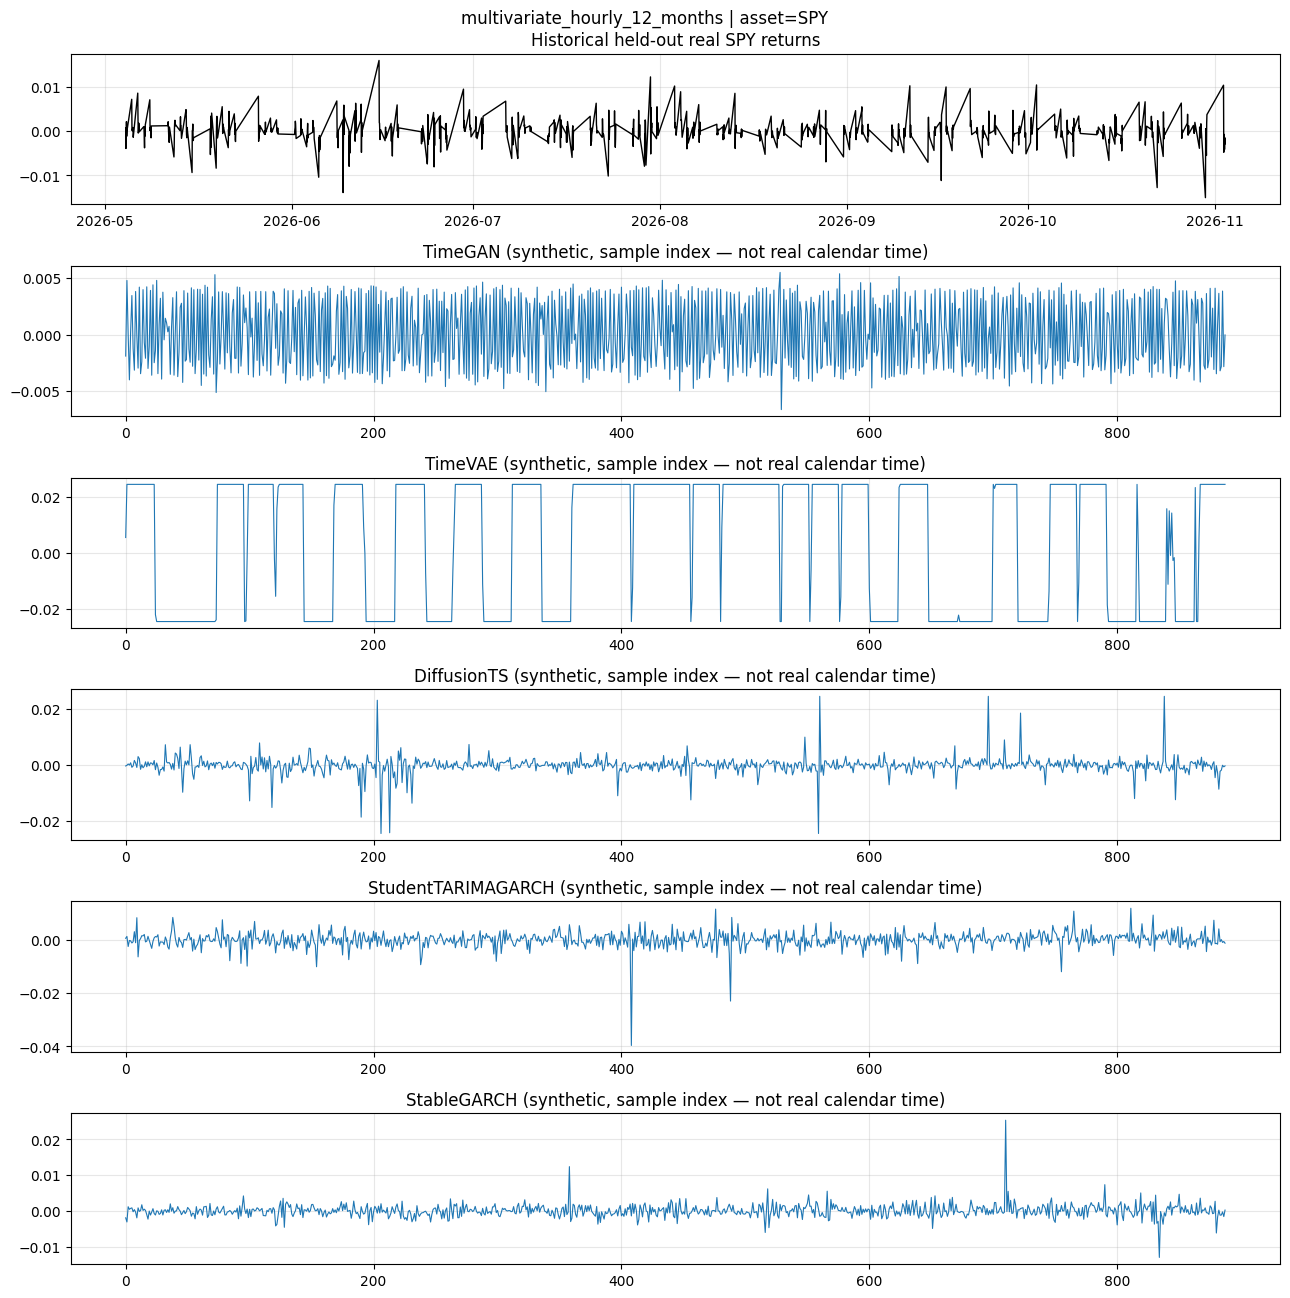

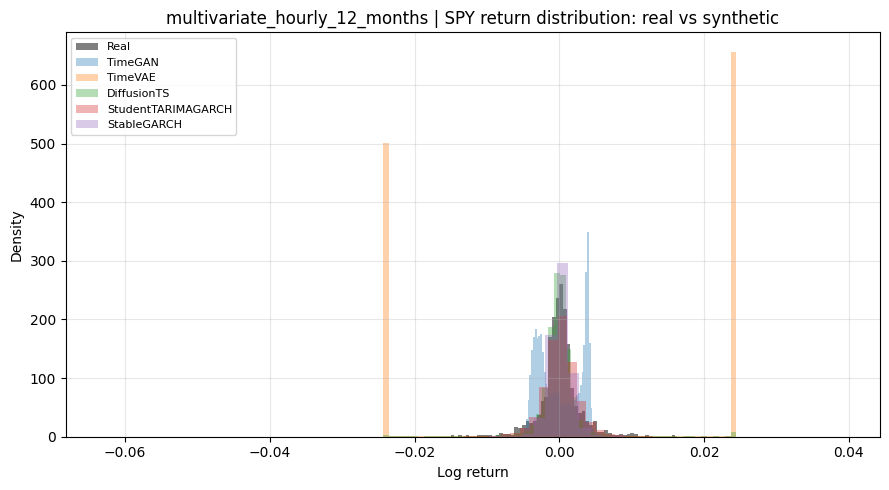

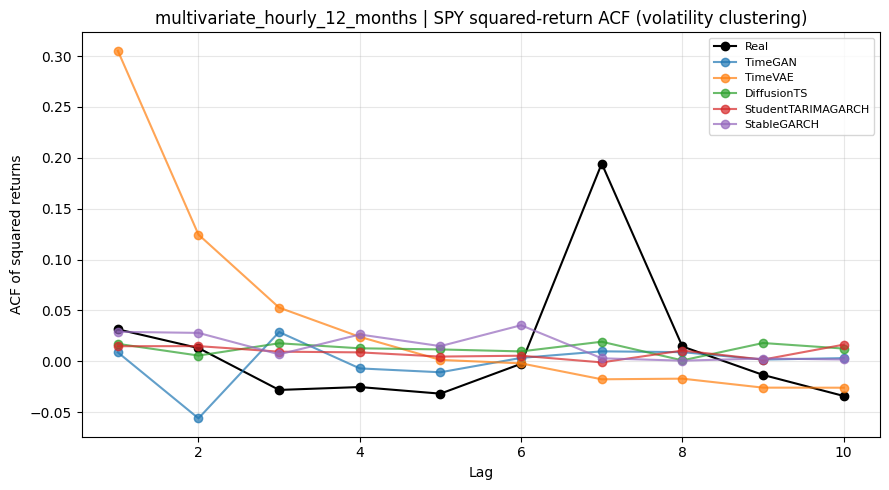

In [19]:
all_results = []

for data_config_name in DATA_CONFIGS:
    for time_cfg in ALL_TIME_CONFIGS:
        if not time_cfg["available"]:
            print(f"skipping {data_config_name}/{time_cfg['frequency']}/{time_cfg['label']}: {time_cfg['note']}")
            continue
        res, asset_res = run_experiment(data_config_name, time_cfg)
        if res is not None:
            all_results.append(res)


## 14. Results tables, rankings, and summary — NOT executed in this delivered notebook

Univariate-SPY and multivariate results are kept in clearly separate tables/rankings throughout,
never merged into one ranking.



=== multivariate rankings ===

multivariate / daily:


,Model,Training Duration,Composite Error Score,Model Status
38,StudentTARIMAGARCH,5_years,0.533135,ok
43,StudentTARIMAGARCH,8_years,0.536191,ok
33,StudentTARIMAGARCH,2_years,0.549766,ok
34,StableGARCH,2_years,0.550207,ok
32,DiffusionTS,2_years,0.566285,ok
44,StableGARCH,8_years,0.573382,ok
39,StableGARCH,5_years,0.577045,ok
30,TimeGAN,2_years,0.591600,ok
42,DiffusionTS,8_years,0.596039,ok
35,TimeGAN,5_years,0.608793,ok



multivariate / hourly:


,Model,Training Duration,Composite Error Score,Model Status
55,TimeGAN,12_months,0.539915,ok
57,DiffusionTS,12_months,0.554434,ok
45,TimeGAN,3_months,0.559880,ok
50,TimeGAN,6_months,0.583126,ok
48,StudentTARIMAGARCH,3_months,0.585568,ok
47,DiffusionTS,3_months,0.588389,ok
58,StudentTARIMAGARCH,12_months,0.589578,ok
52,DiffusionTS,6_months,0.608317,ok
53,StudentTARIMAGARCH,6_months,0.613765,ok
49,StableGARCH,3_months,0.613887,ok



=== univariate_spy rankings ===

univariate_spy / daily:


,Model,Training Duration,Composite Error Score,Model Status
8,StudentTARIMAGARCH,5_years,0.395550,ok
13,StudentTARIMAGARCH,8_years,0.417438,ok
3,StudentTARIMAGARCH,2_years,0.433275,ok
9,StableGARCH,5_years,0.440962,ok
4,StableGARCH,2_years,0.446170,ok
7,DiffusionTS,5_years,0.448076,ok
2,DiffusionTS,2_years,0.450616,ok
12,DiffusionTS,8_years,0.459380,ok
14,StableGARCH,8_years,0.467120,ok
10,TimeGAN,8_years,0.496302,ok


... (2 outputs left out)


Composite score vs training duration:


Frequency                                 daily                        hourly  \
Training Duration                       2_years   5_years   8_years 12_months   
Data Configuration Model                                                        
multivariate       DiffusionTS         0.566285  0.627425  0.596039  0.554434   
                   StableGARCH         0.550207  0.577045  0.573382  0.626175   
                   StudentTARIMAGARCH  0.549766  0.533135  0.536191  0.589578   
                   TimeGAN             0.591600  0.608793  0.624594  0.539915   
                   TimeVAE             0.715325  0.755073  0.752437  0.735110   
univariate_spy     DiffusionTS         0.450616  0.448076  0.459380  0.419289   
                   StableGARCH         0.446170  0.440962  0.467120  0.408608   
                   StudentTARIMAGARCH  0.433275  0.395550  0.417438  0.297228   
                   TimeGAN             0.548635  0.530345  0.496302  0.346126   
                   TimeVAE             0.518991  0.605764  0.588697  0.473111   

Frequency                                                  
Training Duration                      3_months  6_months  
Data Configuration Model                                   
multivariate       DiffusionTS         0.588389  0.608317  
                   StableGARCH         0.613887  0.639382  
                   StudentTARIMAGARCH  0.585568  0.613765  
                   TimeGAN             0.559880  0.583126  
                   TimeVAE             0.738508  0.741856  
univariate_spy     DiffusionTS         0.342577  0.392392  
                   StableGARCH         0.402441  0.408789  
                   StudentTARIMAGARCH  0.351199  0.312566  
                   TimeGAN             0.414207  0.359367  
                   TimeVAE             0.558516  0.525438


Metric-wise winners per experiment:


predictive_score discriminative_score  \
multivariate   daily  2_years    StudentTARIMAGARCH          StableGARCH   
                      5_years    StudentTARIMAGARCH   StudentTARIMAGARCH   
                      8_years    StudentTARIMAGARCH          StableGARCH   
               hourly 12_months  StudentTARIMAGARCH          StableGARCH   
                      3_months          StableGARCH          StableGARCH   
                      6_months   StudentTARIMAGARCH          StableGARCH   
univariate_spy daily  2_years           DiffusionTS          StableGARCH   
                      5_years    StudentTARIMAGARCH          StableGARCH   
                      8_years           StableGARCH          StableGARCH   
               hourly 12_months         DiffusionTS          StableGARCH   
                      3_months          StableGARCH          StableGARCH   
                      6_months   StudentTARIMAGARCH          StableGARCH   

                                raw_return_acf_error  \
multivariate   daily  2_years            DiffusionTS   
                      5_years     StudentTARIMAGARCH   
                      8_years     StudentTARIMAGARCH   
               hourly 12_months          DiffusionTS   
                      3_months           StableGARCH   
                      6_months    StudentTARIMAGARCH   
univariate_spy daily  2_years            DiffusionTS   
                      5_years     StudentTARIMAGARCH   
                      8_years     StudentTARIMAGARCH   
               hourly 12_months          DiffusionTS   
                      3_months    StudentTARIMAGARCH   
                      6_months    StudentTARIMAGARCH   

                                volatility_clustering_error  \
multivariate   daily  2_years                   DiffusionTS   
                      5_years            StudentTARIMAGARCH   
                      8_years            StudentTARIMAGARCH   
               hourly 12_months          StudentTARIMAGARCH   
                      3_months                  StableGARCH   
                      6_months                  StableGARCH   
univariate_spy daily  2_years                   DiffusionTS   
                      5_years            StudentTARIMAGARCH   
                      8_years            StudentTARIMAGARCH   
               hourly 12_months                 DiffusionTS   
                      3_months           StudentTARIMAGARCH   
                      6_months           StudentTARIMAGARCH   

                                  correlation_error          hill_error  \
multivariate   daily  2_years           DiffusionTS  StudentTARIMAGARCH   
                      5_years           DiffusionTS  StudentTARIMAGARCH   
                      8_years           DiffusionTS         DiffusionTS   
               hourly 12_months         DiffusionTS             TimeGAN   
                      3_months              TimeGAN             TimeGAN   
                      6_months          DiffusionTS         DiffusionTS   
univariate_spy daily  2_years               TimeGAN  StudentTARIMAGARCH   
                      5_years               TimeGAN  StudentTARIMAGARCH   
                      8_years           DiffusionTS         DiffusionTS   
               hourly 12_months  StudentTARIMAGARCH  StudentTARIMAGARCH   
                      3_months   StudentTARIMAGARCH         DiffusionTS   
                      6_months              TimeGAN         DiffusionTS   

                                     spectral_error      skewness_error  \
multivariate   daily  2_years               TimeGAN         StableGARCH   
                      5_years           DiffusionTS  StudentTARIMAGARCH   
                      8_years           StableGARCH             TimeGAN   
               hourly 12_months         StableGARCH             TimeGAN   
                      3_months          DiffusionTS             TimeGAN   
                      6_months          DiffusionTS             TimeGAN

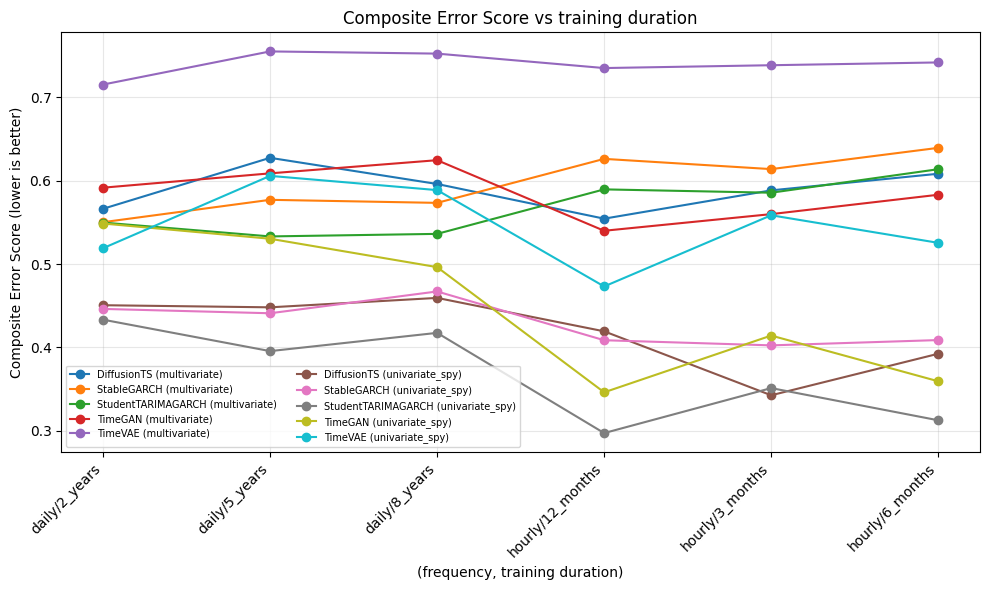

In [21]:
def summarize_all(all_results):
    if not all_results:
        print("No experiment results available yet — run Section 13 first.")
        return None

    combined = pd.concat(all_results, ignore_index=True)
    combined.to_csv(PROJECT_CONFIG["results_dir"] / "combined_results.csv", index=False)

    tables = {}
    for data_cfg, group in combined.groupby("Data Configuration"):
        print(f"\n=== {data_cfg} rankings ===")
        for freq, subgroup in group.groupby("Frequency"):
            ranking = subgroup.sort_values("Composite Error Score")[
                ["Model", "Training Duration", "Composite Error Score", "Model Status"]]
            print(f"\n{data_cfg} / {freq}:")
            display(ranking)
            tables[(data_cfg, freq)] = ranking

    duration_comparison = combined.pivot_table(
        index=["Data Configuration", "Model"], columns=["Frequency", "Training Duration"],
        values="Composite Error Score", aggfunc="mean")
    print("\nComposite score vs training duration:")
    display(duration_comparison)

    metric_cols = [c for c in combined.columns if c in COMPOSITE_CONFIG["tau"]]
    winners = {}
    for (data_cfg, freq, dur), group in combined.groupby(["Data Configuration", "Frequency", "Training Duration"]):
        winners[(data_cfg, freq, dur)] = {
            m: (group.loc[group[m].idxmin(), "Model"] if group[m].notna().any() else None) for m in metric_cols}
    winners_df = pd.DataFrame(winners).T
    print("\nMetric-wise winners per experiment:")
    display(winners_df)

    fig, ax = plt.subplots(figsize=(10, 6))
    x_labels = ["/".join(str(level) for level in col) for col in duration_comparison.columns]
    x_positions = np.arange(len(x_labels))
    for (data_cfg, model), row in duration_comparison.iterrows():
        ax.plot(x_positions, row.values, marker="o", label=f"{model} ({data_cfg})")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, rotation=45, ha="right")
    ax.set_title("Composite Error Score vs training duration")
    ax.set_xlabel("(frequency, training duration)"); ax.set_ylabel("Composite Error Score (lower is better)")
    ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(PROJECT_CONFIG["results_dir"] / "composite_vs_duration.png", dpi=150)
    plt.show()
    plt.close(fig)

    return dict(combined=combined, tables=tables, duration_comparison=duration_comparison, winners=winners_df)

summary = summarize_all(all_results)

In [23]:
def show_metric_breakdown_by_segment(combined):
    if combined is None or len(combined) == 0:
        print("No combined results available — run Section 13 and summarize_all first.")
        return {}

    metric_cols = [c for c in combined.columns if c in COMPOSITE_CONFIG["tau"]]
    segments = [
        ("multivariate", "daily"),
        ("multivariate", "hourly"),
        ("univariate_spy", "daily"),
        ("univariate_spy", "hourly"),
    ]

    breakdown_tables = {}
    for data_cfg, freq in segments:
        subset = combined[(combined["Data Configuration"] == data_cfg) & (combined["Frequency"] == freq)]
        print(f"\n=== {data_cfg} / {freq} — per-metric performance by model "
              f"(mean across training durations, NaN preserved, never treated as zero) ===")
        if len(subset) == 0:
            print("  no completed experiments for this segment")
            breakdown_tables[(data_cfg, freq)] = pd.DataFrame()
            continue

        table = subset.groupby("Model")[metric_cols + ["Composite Error Score"]].mean(numeric_only=True)
        table = table.sort_values("Composite Error Score")
        display(table)
        breakdown_tables[(data_cfg, freq)] = table

    return breakdown_tables

metric_breakdown_by_segment = show_metric_breakdown_by_segment(summary["combined"] if summary is not None else None)


=== multivariate / daily — per-metric performance by model (mean across training durations, NaN preserved, never treated as zero) ===


,predictive_score,discriminative_score,raw_return_acf_error,volatility_clustering_error,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,leverage_effect_error,Composite Error Score
Model,,,,,,,,,,,,
StudentTARIMAGARCH,0.964159,0.068063,0.344692,0.628360,2.949913,0.171528,2.011018,0.482217,4.946196,0.008213,0.517123,0.539697
StableGARCH,0.975162,0.054101,0.360200,0.856076,2.943632,0.206556,1.837451,0.442764,6.064977,0.018789,0.501280,0.566878
DiffusionTS,0.987412,0.685864,0.345167,0.621620,2.199070,0.245774,1.855230,1.337114,9.171592,0.010720,0.515716,0.596583
TimeGAN,1.016287,0.165794,1.256258,0.907281,3.415540,0.236826,1.758705,0.450000,8.002390,0.011267,0.742600,0.608329
TimeVAE,1.625680,0.912740,6.299518,3.535467,3.039636,0.286832,43.240940,0.588371,8.558410,0.072350,4.817418,0.740945



=== multivariate / hourly — per-metric performance by model (mean across training durations, NaN preserved, never treated as zero) ===


,predictive_score,discriminative_score,raw_return_acf_error,volatility_clustering_error,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,leverage_effect_error,Composite Error Score
Model,,,,,,,,,,,,
TimeGAN,1.175495,0.085495,1.518084,0.724757,2.907223,0.127133,1.890218,0.380307,10.274396,0.005687,0.479118,0.560974
DiffusionTS,0.990786,0.465898,0.298757,0.725606,2.700632,0.130277,1.349623,2.892619,20.397094,0.008103,0.395050,0.583714
StudentTARIMAGARCH,0.913255,0.050913,0.267114,0.491661,3.385963,0.288089,3.016178,5.779407,622.234354,0.004227,0.204608,0.596304
StableGARCH,0.925933,0.006724,0.269129,0.460589,3.390303,0.550968,10.227488,28.266884,3160.349136,0.007519,0.198531,0.626481
TimeVAE,1.494443,0.859750,6.281255,3.309178,3.652433,0.157660,71.936515,0.594416,10.508855,0.042094,3.998543,0.738491



=== univariate_spy / daily — per-metric performance by model (mean across training durations, NaN preserved, never treated as zero) ===


,predictive_score,discriminative_score,raw_return_acf_error,volatility_clustering_error,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,leverage_effect_error,Composite Error Score
Model,,,,,,,,,,,,
StudentTARIMAGARCH,1.003181,0.068063,0.452449,0.619412,1.850372e-16,0.237459,1.592320,0.881796,16.036847,0.002528,0.696137,0.415421
StableGARCH,1.003607,0.005236,0.557725,0.784068,1.850372e-16,0.330382,1.300646,0.868801,20.274168,0.010104,0.663349,0.451417
DiffusionTS,1.019618,0.029668,0.485306,0.815830,9.934107e-08,0.305393,1.449975,1.409018,17.369905,0.008157,0.571933,0.452691
TimeGAN,1.033965,0.165794,3.289165,2.239879,3.973643e-08,0.409051,1.735673,1.234889,18.775455,0.010692,1.593358,0.525094
TimeVAE,3.990560,0.647469,4.581311,2.958746,1.688798e-06,0.430222,60.157111,0.193850,21.810813,0.065656,3.901424,0.571151



=== univariate_spy / hourly — per-metric performance by model (mean across training durations, NaN preserved, never treated as zero) ===


,predictive_score,discriminative_score,raw_return_acf_error,volatility_clustering_error,correlation_error,hill_error,spectral_error,skewness_error,kurtosis_error,var_error_asset,leverage_effect_error,Composite Error Score
Model,,,,,,,,,,,,
StudentTARIMAGARCH,1.040706,0.048991,0.251553,0.390624,1.480297e-16,0.161977,2.191016,0.178037,51.354337,0.002207,0.215957,0.320331
TimeGAN,1.125667,0.077810,1.141416,0.724852,7.947286e-08,0.126588,2.184740,0.373973,6.396329,0.001188,0.686784,0.373233
DiffusionTS,1.382243,0.156580,0.296402,0.549399,1.390775e-07,0.164425,1.983595,1.819244,23.237317,0.004266,0.306039,0.384752
StableGARCH,1.019116,0.008646,0.258213,0.406937,2.220446e-16,0.225850,1.661523,4.042902,174.896124,0.001977,0.215632,0.406613
TimeVAE,2.318702,0.454371,4.689636,1.100845,2.106031e-06,0.183501,64.480640,0.687736,6.883487,0.018233,1.816467,0.519022


In [24]:
def load_all_asset_level_results():
    rows = []
    for asset_csv in PROJECT_CONFIG["results_dir"].rglob("asset_metrics.csv"):
        exp_dir = asset_csv.parent
        config_path = exp_dir / "experiment_config.json"
        if not config_path.exists():
            continue
        with open(config_path) as f:
            exp_cfg = json.load(f)
        df = pd.read_csv(asset_csv)
        if len(df) == 0:
            continue
        df["Frequency"] = exp_cfg["frequency"]
        df["Training Duration"] = exp_dir.name
        rows.append(df)

    if not rows:
        return pd.DataFrame()
    return pd.concat(rows, ignore_index=True)

def show_asset_level_breakdown(asset_level_df):
    if asset_level_df is None or len(asset_level_df) == 0:
        print("No asset-level results found on disk yet — run Section 13 first.")
        return {}

    asset_tables = {}
    for data_cfg, data_group in asset_level_df.groupby("data_config"):
        for asset, asset_group in data_group.groupby("asset"):
            print(f"\n=== {data_cfg} | asset={asset} — metric score by model and frequency "
                  f"(mean across training durations, NaN preserved, never treated as zero) ===")
            table = asset_group.pivot_table(index="metric", columns=["Frequency", "model"],
                                             values="value", aggfunc="mean")
            display(table)
            asset_tables[(data_cfg, asset)] = table

    return asset_tables

asset_level_results = load_all_asset_level_results()
asset_level_breakdown = show_asset_level_breakdown(asset_level_results)


=== multivariate | asset=EEM — metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.183547    0.136206           0.119433   
kurtosis_error                13.911386    3.274912           1.898640   
leverage_effect_error          0.607915    0.551330           0.588922   
raw_return_acf_error           0.277894    0.318510           0.316705   
skewness_error                 1.421700    0.325670           0.410105   
spectral_error                 1.600127    1.564771           2.973723   
var_error_asset                0.008190    0.017698           0.018075   
volatility_clustering_error    0.575383    1.002864           0.503464   

Frequency                                             hourly               \
model                         TimeGAN    TimeVAE DiffusionTS  StableGARCH   
metric                                                                      
hill_error                   0.145129   0.202155    0.094887     0.687371   
kurtosis_error               5.063506   5.640550   16.110015  4154.557702   
leverage_effect_error        0.857115   4.851892    0.301065     0.082496   
raw_return_acf_error         1.126835   5.664816    0.224619     0.220503   
skewness_error               0.319247   0.189041    1.466342    48.830961   
spectral_error               1.533715  36.235612    1.217539     5.307109   
var_error_asset              0.010370   0.072091    0.009874     0.008372   
volatility_clustering_error  0.952891   3.782914    0.841943     0.440093   

Frequency                                                             
model                       StudentTARIMAGARCH    TimeGAN    TimeVAE  
metric                                                                
hill_error                            0.227921   0.210394   0.242874  
kurtosis_error                      286.343822  14.292500  14.719733  
leverage_effect_error                 0.128910   0.390036   5.261209  
raw_return_acf_error                  0.271273   1.566377   5.871588  
skewness_error                        2.996458   0.929434   0.511904  
spectral_error                        2.682630   1.549516  99.766955  
var_error_asset                       0.006433   0.009606   0.061879  
volatility_clustering_error           0.486879   0.848793   5.063459


=== multivariate | asset=GLD — metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.298216    0.347184           0.235317   
kurtosis_error                 5.398918    5.763344           3.344147   
leverage_effect_error          0.365799    0.327506           0.345632   
raw_return_acf_error           0.291040    0.328523           0.345140   
skewness_error                 0.785583    0.997378           0.920797   
spectral_error                 1.173093    1.088011           1.443299   
var_error_asset                0.014164    0.023403           0.007927   
volatility_clustering_error    0.428945    0.645119           0.506228   

Frequency                                            hourly              \
model                         TimeGAN   TimeVAE DiffusionTS StableGARCH   
metric                                                                    
hill_error                   0.367294  0.428874    0.107294    1.135086   
kurtosis_error               6.739427  7.377176   66.372085  689.482797   
leverage_effect_error        0.555751  4.742783    0.448173    0.219231   
raw_return_acf_error         1.271963  6.711544    0.184258    0.206105   
skewness_error               0.993680  0.342378    5.843453    5.815966   
spectral_error               1.171898  8.282096    1.060858    4.392017   
var_error_asset              0.018512  0.017601    0.010187    0.009763   
volatility_clustering_error  0.942680  2.203355    0.887960    0.593733   

Frequency                                                              
model                       StudentTARIMAGARCH    TimeGAN     TimeVAE  
metric                                                                 
hill_error                            0.416312   0.094506    0.125705  
kurtosis_error                     2413.321407  12.915407   13.306623  
leverage_effect_error                 0.173819   0.803684    4.485274  
raw_return_acf_error                  0.206530   1.519930    6.702601  
skewness_error                       21.923057   0.257484    0.791367  
spectral_error                        3.088367   1.809578  122.948452  
var_error_asset                       0.003378   0.005677    0.060634  
volatility_clustering_error           0.460397   0.774777    4.123540


=== multivariate | asset=IWM — metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.240855    0.189712           0.074962   
kurtosis_error                 8.790817    4.079625           1.735116   
leverage_effect_error          0.550868    0.563679           0.488056   
raw_return_acf_error           0.351089    0.311467           0.286278   
skewness_error                 1.130908    0.081107           0.184756   
spectral_error                 2.016283    1.709383           1.854502   
var_error_asset                0.008140    0.012113           0.002873   
volatility_clustering_error    0.736598    0.859671           0.659933   

Frequency                                             hourly                \
model                         TimeGAN    TimeVAE DiffusionTS   StableGARCH   
metric                                                                       
hill_error                   0.231955   0.285461    0.108897      0.560813   
kurtosis_error               5.823450   6.137513    9.758079  12938.934824   
leverage_effect_error        0.787254   5.582446    0.462833      0.206596   
raw_return_acf_error         1.187323   6.273064    0.312479      0.547964   
skewness_error               0.185318   0.566158    1.687841    102.117204   
spectral_error               1.923976  49.975106    1.680694     55.637540   
var_error_asset              0.006498   0.080945    0.002144      0.003789   
volatility_clustering_error  0.800325   4.604506    0.688491      0.532490   

Frequency                                                            
model                       StudentTARIMAGARCH   TimeGAN    TimeVAE  
metric                                                               
hill_error                            0.404495  0.037641   0.051870  
kurtosis_error                      197.106179  6.254503   6.465759  
leverage_effect_error                 0.243687  0.514794   5.126115  
raw_return_acf_error                  0.323197  1.601333   6.307866  
skewness_error                        1.882870  0.232922   0.835438  
spectral_error                        3.495021  2.464841  67.742114  
var_error_asset                       0.002424  0.003191   0.029211  
volatility_clustering_error           0.497943  0.770662   3.766467

... (6 outputs left out)


=== multivariate | asset=USO — metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.190689    0.101413           0.102533   
kurtosis_error                21.331913    1.980808           1.194991   
leverage_effect_error          0.686507    0.582345           0.647354   
raw_return_acf_error           0.323867    0.313085           0.406748   
skewness_error                 2.674895    0.008992           0.110132   
spectral_error                 1.466891    1.652315           1.789029   
var_error_asset                0.020979    0.036261           0.010365   
volatility_clustering_error    0.914358    0.941298           0.755026   

Frequency                                             hourly              \
model                         TimeGAN    TimeVAE DiffusionTS StableGARCH   
metric                                                                     
hill_error                   0.102885   0.138483    0.062025    0.549131   
kurtosis_error               3.410285   4.326334   28.152807  727.285123   
leverage_effect_error        0.884603   4.069539    0.477088    0.229426   
raw_return_acf_error         1.328290   5.977902    0.339049    0.199994   
skewness_error               0.172932   0.463565    4.533375    9.072074   
spectral_error               1.493773  45.748089    1.064481    1.558575   
var_error_asset              0.023594   0.160664    0.025543    0.019534   
volatility_clustering_error  1.179204   3.063135    0.797767    0.505952   

Frequency                                                             
model                       StudentTARIMAGARCH    TimeGAN    TimeVAE  
metric                                                                
hill_error                            0.390910   0.066388   0.092882  
kurtosis_error                      478.016072  10.766053  11.245814  
leverage_effect_error                 0.213827   0.420796   4.721129  
raw_return_acf_error                  0.275297   1.565634   6.051359  
skewness_error                        3.109664   0.471101   0.942675  
spectral_error                        3.441329   1.969975  91.269383  
var_error_asset                       0.007821   0.013127   0.099349  
volatility_clustering_error           0.521852   0.919042   4.038868


=== univariate_spy | asset=SPY — metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.305393    0.330382           0.237459   
kurtosis_error                17.369905   20.274168          16.036847   
leverage_effect_error          0.571933    0.663349           0.696137   
raw_return_acf_error           0.485306    0.557725           0.452449   
skewness_error                 1.409018    0.868801           0.881796   
spectral_error                 1.449975    1.300646           1.592320   
var_error_asset                0.008157    0.010104           0.002528   
volatility_clustering_error    0.815830    0.784068           0.619412   

Frequency                                              hourly              \
model                          TimeGAN    TimeVAE DiffusionTS StableGARCH   
metric                                                                      
hill_error                    0.409051   0.430222    0.164425    0.225850   
kurtosis_error               18.775455  21.810813   23.237317  174.896124   
leverage_effect_error         1.593358   3.901424    0.306039    0.215632   
raw_return_acf_error          3.289165   4.581311    0.296402    0.258213   
skewness_error                1.234889   0.193850    1.819244    4.042902   
spectral_error                1.735673  60.157111    1.983595    1.661523   
var_error_asset               0.010692   0.065656    0.004266    0.001977   
volatility_clustering_error   2.239879   2.958746    0.549399    0.406937   

Frequency                                                            
model                       StudentTARIMAGARCH   TimeGAN    TimeVAE  
metric                                                               
hill_error                            0.161977  0.126588   0.183501  
kurtosis_error                       51.354337  6.396329   6.883487  
leverage_effect_error                 0.215957  0.686784   1.816467  
raw_return_acf_error                  0.251553  1.141416   4.689636  
skewness_error                        0.178037  0.373973   0.687736  
spectral_error                        2.191016  2.184740  64.480640  
var_error_asset                       0.002207  0.001188   0.018233  
volatility_clustering_error           0.390624  0.724852   1.100845

In [25]:
def load_all_asset_level_results():
    rows = []
    for asset_csv in PROJECT_CONFIG["results_dir"].rglob("asset_metrics.csv"):
        exp_dir = asset_csv.parent
        config_path = exp_dir / "experiment_config.json"
        if not config_path.exists():
            continue
        with open(config_path) as f:
            exp_cfg = json.load(f)
        df = pd.read_csv(asset_csv)
        if len(df) == 0:
            continue
        df["Frequency"] = exp_cfg["frequency"]
        df["Training Duration"] = exp_dir.name
        rows.append(df)

    if not rows:
        return pd.DataFrame()
    return pd.concat(rows, ignore_index=True)

JOINT_MULTIVARIATE_METRICS = ["correlation_error", "var_error_portfolio", "discriminative_score", "predictive_score"]

def show_asset_level_breakdown(asset_level_df, combined):
    if asset_level_df is None or len(asset_level_df) == 0:
        print("No asset-level results found on disk yet — run Section 13 first.")
        return {}

    asset_tables = {}
    for data_cfg, data_group in asset_level_df.groupby("data_config"):
        for asset, asset_group in data_group.groupby("asset"):
            print(f"\n=== {data_cfg} | asset={asset} — PER-ASSET metric score by model and frequency "
                  f"(mean across training durations, NaN preserved, never treated as zero) ===")
            table = asset_group.pivot_table(index="metric", columns=["Frequency", "model"],
                                             values="value", aggfunc="mean")
            display(table)
            asset_tables[(data_cfg, asset)] = table

    print("\n--- NOTE ---")
    print("correlation_error, var_error_portfolio, discriminative_score, and predictive_score are "
          "NEVER computed per asset by metrics.py: they are called on the full multivariate window "
          "jointly (see evaluate_model_metrics in Section 9), not sliced per feature like the 8 "
          "metrics above. They cannot be meaningfully broken down by asset, so they are shown below "
          "at the only granularity that actually exists for them: (data_config, frequency, model).")

    joint_tables = {}
    if combined is not None and len(combined) > 0:
        available_joint_cols = [c for c in JOINT_MULTIVARIATE_METRICS if c in combined.columns]
        for data_cfg, data_group in combined.groupby("Data Configuration"):
            print(f"\n=== {data_cfg} — JOINT/multivariate metric score by model and frequency "
                  f"(mean across training durations, NaN preserved, never treated as zero) ===")
            table = data_group.groupby(["Frequency", "Model"])[available_joint_cols].mean(numeric_only=True)
            display(table)
            joint_tables[data_cfg] = table
    else:
        print("No experiment-level combined results available (run summarize_all first) — "
              "joint/multivariate metric tables skipped.")

    return {"per_asset": asset_tables, "joint_multivariate": joint_tables}

asset_level_results = load_all_asset_level_results()
asset_level_breakdown = show_asset_level_breakdown(
    asset_level_results, summary["combined"] if summary is not None else None)



=== multivariate | asset=EEM — PER-ASSET metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.183547    0.136206           0.119433   
kurtosis_error                13.911386    3.274912           1.898640   
leverage_effect_error          0.607915    0.551330           0.588922   
raw_return_acf_error           0.277894    0.318510           0.316705   
skewness_error                 1.421700    0.325670           0.410105   
spectral_error                 1.600127    1.564771           2.973723   
var_error_asset                0.008190    0.017698           0.018075   
volatility_clustering_error    0.575383    1.002864           0.503464   

Frequency                                             hourly               \
model                         TimeGAN    TimeVAE DiffusionTS  StableGARCH   
metric                                                                      
hill_error                   0.145129   0.202155    0.094887     0.687371   
kurtosis_error               5.063506   5.640550   16.110015  4154.557702   
leverage_effect_error        0.857115   4.851892    0.301065     0.082496   
raw_return_acf_error         1.126835   5.664816    0.224619     0.220503   
skewness_error               0.319247   0.189041    1.466342    48.830961   
spectral_error               1.533715  36.235612    1.217539     5.307109   
var_error_asset              0.010370   0.072091    0.009874     0.008372   
volatility_clustering_error  0.952891   3.782914    0.841943     0.440093   

Frequency                                                             
model                       StudentTARIMAGARCH    TimeGAN    TimeVAE  
metric                                                                
hill_error                            0.227921   0.210394   0.242874  
kurtosis_error                      286.343822  14.292500  14.719733  
leverage_effect_error                 0.128910   0.390036   5.261209  
raw_return_acf_error                  0.271273   1.566377   5.871588  
skewness_error                        2.996458   0.929434   0.511904  
spectral_error                        2.682630   1.549516  99.766955  
var_error_asset                       0.006433   0.009606   0.061879  
volatility_clustering_error           0.486879   0.848793   5.063459


=== multivariate | asset=GLD — PER-ASSET metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.298216    0.347184           0.235317   
kurtosis_error                 5.398918    5.763344           3.344147   
leverage_effect_error          0.365799    0.327506           0.345632   
raw_return_acf_error           0.291040    0.328523           0.345140   
skewness_error                 0.785583    0.997378           0.920797   
spectral_error                 1.173093    1.088011           1.443299   
var_error_asset                0.014164    0.023403           0.007927   
volatility_clustering_error    0.428945    0.645119           0.506228   

Frequency                                            hourly              \
model                         TimeGAN   TimeVAE DiffusionTS StableGARCH   
metric                                                                    
hill_error                   0.367294  0.428874    0.107294    1.135086   
kurtosis_error               6.739427  7.377176   66.372085  689.482797   
leverage_effect_error        0.555751  4.742783    0.448173    0.219231   
raw_return_acf_error         1.271963  6.711544    0.184258    0.206105   
skewness_error               0.993680  0.342378    5.843453    5.815966   
spectral_error               1.171898  8.282096    1.060858    4.392017   
var_error_asset              0.018512  0.017601    0.010187    0.009763   
volatility_clustering_error  0.942680  2.203355    0.887960    0.593733   

Frequency                                                              
model                       StudentTARIMAGARCH    TimeGAN     TimeVAE  
metric                                                                 
hill_error                            0.416312   0.094506    0.125705  
kurtosis_error                     2413.321407  12.915407   13.306623  
leverage_effect_error                 0.173819   0.803684    4.485274  
raw_return_acf_error                  0.206530   1.519930    6.702601  
skewness_error                       21.923057   0.257484    0.791367  
spectral_error                        3.088367   1.809578  122.948452  
var_error_asset                       0.003378   0.005677    0.060634  
volatility_clustering_error           0.460397   0.774777    4.123540


=== multivariate | asset=IWM — PER-ASSET metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


Frequency                         daily                                 \
model                       DiffusionTS StableGARCH StudentTARIMAGARCH   
metric                                                                   
hill_error                     0.240855    0.189712           0.074962   
kurtosis_error                 8.790817    4.079625           1.735116   
leverage_effect_error          0.550868    0.563679           0.488056   
raw_return_acf_error           0.351089    0.311467           0.286278   
skewness_error                 1.130908    0.081107           0.184756   
spectral_error                 2.016283    1.709383           1.854502   
var_error_asset                0.008140    0.012113           0.002873   
volatility_clustering_error    0.736598    0.859671           0.659933   

Frequency                                             hourly                \
model                         TimeGAN    TimeVAE DiffusionTS   StableGARCH   
metric                                                                       
hill_error                   0.231955   0.285461    0.108897      0.560813   
kurtosis_error               5.823450   6.137513    9.758079  12938.934824   
leverage_effect_error        0.787254   5.582446    0.462833      0.206596   
raw_return_acf_error         1.187323   6.273064    0.312479      0.547964   
skewness_error               0.185318   0.566158    1.687841    102.117204   
spectral_error               1.923976  49.975106    1.680694     55.637540   
var_error_asset              0.006498   0.080945    0.002144      0.003789   
volatility_clustering_error  0.800325   4.604506    0.688491      0.532490   

Frequency                                                            
model                       StudentTARIMAGARCH   TimeGAN    TimeVAE  
metric                                                               
hill_error                            0.404495  0.037641   0.051870  
kurtosis_error                      197.106179  6.254503   6.465759  
leverage_effect_error                 0.243687  0.514794   5.126115  
raw_return_acf_error                  0.323197  1.601333   6.307866  
skewness_error                        1.882870  0.232922   0.835438  
spectral_error                        3.495021  2.464841  67.742114  
var_error_asset                       0.002424  0.003191   0.029211  
volatility_clustering_error           0.497943  0.770662   3.766467

... (10 outputs left out)


--- NOTE ---
correlation_error, var_error_portfolio, discriminative_score, and predictive_score are NEVER computed per asset by metrics.py: they are called on the full multivariate window jointly (see evaluate_model_metrics in Section 9), not sliced per feature like the 8 metrics above. They cannot be meaningfully broken down by asset, so they are shown below at the only granularity that actually exists for them: (data_config, frequency, model).

=== multivariate — JOINT/multivariate metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


correlation_error  var_error_portfolio  \
Frequency Model                                                        
daily     DiffusionTS                  2.199070             0.007219   
          StableGARCH                  2.943632             0.008337   
          StudentTARIMAGARCH           2.949913             0.005927   
          TimeGAN                      3.415540             0.005180   
          TimeVAE                      3.039636             0.075251   
hourly    DiffusionTS                  2.700632             0.003072   
          StableGARCH                  3.390303             0.002893   
          StudentTARIMAGARCH           3.385963             0.001617   
          TimeGAN                      2.907223             0.003020   
          TimeVAE                      3.652433             0.045449   

                              discriminative_score  predictive_score  
Frequency Model                                                       
daily     DiffusionTS                     0.685864          0.987412  
          StableGARCH                     0.054101          0.975162  
          StudentTARIMAGARCH              0.068063          0.964159  
          TimeGAN                         0.165794          1.016287  
          TimeVAE                         0.912740          1.625680  
hourly    DiffusionTS                     0.465898          0.990786  
          StableGARCH                     0.006724          0.925933  
          StudentTARIMAGARCH              0.050913          0.913255  
          TimeGAN                         0.085495          1.175495  
          TimeVAE                         0.859750          1.494443


=== univariate_spy — JOINT/multivariate metric score by model and frequency (mean across training durations, NaN preserved, never treated as zero) ===


correlation_error  var_error_portfolio  \
Frequency Model                                                        
daily     DiffusionTS              9.934107e-08             0.008157   
          StableGARCH              1.850372e-16             0.010104   
          StudentTARIMAGARCH       1.850372e-16             0.002528   
          TimeGAN                  3.973643e-08             0.010692   
          TimeVAE                  1.688798e-06             0.065656   
hourly    DiffusionTS              1.390775e-07             0.004266   
          StableGARCH              2.220446e-16             0.001977   
          StudentTARIMAGARCH       1.480297e-16             0.002207   
          TimeGAN                  7.947286e-08             0.001188   
          TimeVAE                  2.106031e-06             0.018233   

                              discriminative_score  predictive_score  
Frequency Model                                                       
daily     DiffusionTS                     0.029668          1.019618  
          StableGARCH                     0.005236          1.003607  
          StudentTARIMAGARCH              0.068063          1.003181  
          TimeGAN                         0.165794          1.033965  
          TimeVAE                         0.647469          3.990560  
hourly    DiffusionTS                     0.156580          1.382243  
          StableGARCH                     0.008646          1.019116  
          StudentTARIMAGARCH              0.048991          1.040706  
          TimeGAN                         0.077810          1.125667  
          TimeVAE                         0.454371          2.318702

## 15. Limitations and reproducibility notes

- **This notebook has not been executed.** No cell in Sections 13–14 has produced real numbers; the
  `smoke_test()` and experiment loops are deliberately left commented out, per instruction.
- **DiffusionTS is the least paper-faithful model in this project** (see the fidelity review above):
  linear rather than cosine noise schedule, no Fourier-domain loss term (despite this project scoring
  spectral fidelity directly), and only standard DDPM ancestral sampling. Any strong claim about
  DiffusionTS's performance should be read in light of this gap, not as a statement about the
  published method.
- **TimeVAE's seasonality block is a sinusoidal approximation**, not the paper's learned per-period
  seasonal table — "trend + seasonality + residual" interpretability is preserved structurally, but
  the seasonal mechanism itself differs.
- **TimeGAN's adversarial training loop omits the official generator:discriminator update ratio and
  discriminator-loss gating**; three-stage training and loss design otherwise match.
- **StableGARCH's parameter estimation is explicitly approximate** (Hill-tail/quantile-based, not full
  stable MLE) — documented in `models.py` and repeated here for visibility.
- **StudentTARIMAGARCH and StableGARCH fit one univariate model per asset.** Their multivariate
  samples do not reproduce cross-asset correlation, joint tail dependence, or covarying volatility —
  this is stated on every relevant results row (`Note` column), not just here.
- **Training budgets for the three neural models are computationally constrained adaptations**
  (`epochs=200` etc.), not reproductions of paper-scale training; see `TRAINING_BUDGET_NOTES`.
  Increase them before drawing any conclusion about a neural model's ceiling performance.
- **Predictive Score** uses `metrics.py`'s existing implementation (next-step, all-features GRU
  regression) as the "configured downstream task" per the original project brief, since it is a
  complete runnable implementation rather than a placeholder — this is a notebook-level interpretation
  choice, not a claim that this is *the* downstream task your professor will ultimately want.
- Exact numerical reproducibility across machines is **not guaranteed** even with fixed seeds, due to
  nondeterministic GPU kernels, BLAS/LAPACK backend differences, and floating-point non-associativity
  across hardware.
